
*   Alumno: Gabriel Ramirez Orozco
*   Matricula: AL02626506
*   Profesor: Tania Judith Mendoza Torres
*   Actividad: 4
*   Fecha: 11/10/2026


In [ ]:
#Paso 1: Instalacion de dependencias
%pip install -q \
    "pandas==2.2.3" \
    "pyarrow==23.0.1" \
    "datasets==3.6.0" \
    "gcsfs==2025.3.0" \
    "fsspec==2025.3.0" \
    "transformers==5.18.0" \
    "huggingface_hub" \
    "scikit-learn==1.6.1" \
    "matplotlib" \
    "seaborn" \
    "pillow" \
    "timm" \
    "accelerate" \
    "safetensors" \
    "jedi"

In [ ]:
#Paso 2: Configuracion del entorno

import torch
import platform

print("______________________________________________________\n")
print("\t\tCONFIGURACION DEL ENTORNO")
print("______________________________________________________")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("CUDA disponible:", torch.cuda.is_available())
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    memoria = (
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3
    )
    print("Memoria GPU:", round(memoria, 2), "GB")


______________________________________________________

		CONFIGURACION DEL ENTORNO
______________________________________________________
Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA disponible: True
Dispositivo: cuda
GPU: Tesla T4
Memoria GPU: 14.56 GB


In [ ]:

#Paso 3: verificacion de librerias y dependencias

import pandas as pd
import pyarrow
import datasets
import transformers
import sklearn
import timm
import huggingface_hub

print("______________________________________________________\n")
print("\t\tVERSIONES")
print("______________________________________________________")
print("Pandas:", pd.__version__)
print("PyArrow:", pyarrow.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TIMM:", timm.__version__)
print("Hugging Face:", huggingface_hub.__version__)

print("\nVerificacion completada.")


______________________________________________________

		VERSIONES
______________________________________________________
Pandas: 2.2.3
PyArrow: 23.0.1
Datasets: 3.6.0
Transformers: 5.18.0
Scikit-learn: 1.6.1
TIMM: 1.0.30
Hugging Face: 1.33.0

Verificacion completada.


In [ ]:


# PASO 4: AUTENTICACION EN HUGGING FACE


from google.colab import userdata
from huggingface_hub import login, whoami

# Obtener token almacenado en Colab
token = userdata.get("HF_TOKEN")

# Autenticacion
login(token=token, add_to_git_credential=False)

# Verificar usuario autenticado
usuario = whoami()

print("=== HUGGING FACE HUB ===")
print("Autenticacion exitosa")
print("Usuario:", usuario["name"])


=== HUGGING FACE HUB ===
Autenticacion exitosa
Usuario: Gabriel27091989


In [ ]:

# PASO 5: CARGA Y ANALISIS DEL DATASET


from datasets import load_dataset

print("\t\tCARGANDO PLANTVILLAGE")
print("______________________________________________________")

dataset = load_dataset(
    "geraldmc/plantvillage-full"
)

print("\t\tESTRUCTURA DEL DATASET")
print("______________________________________________________")
print(dataset)

print("\t\tDIVISIONES DISPONIBLES")
print("______________________________________________________")

for nombre, datos in dataset.items():
    print(nombre, ":", len(datos), "imagenes")

print("\t\tCOLUMNAS")
print("______________________________________________________")

primera_division = list(dataset.keys())[0]
print(dataset[primera_division].column_names)

print("\t\tCARACTERISTICAS")
print("______________________________________________________")
print(dataset[primera_division].features)


		CARGANDO PLANTVILLAGE
______________________________________________________


data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

		ESTRUCTURA DEL DATASET
______________________________________________________
DatasetDict({
    train: Dataset({
        features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
        num_rows: 54304
    })
})
		DIVISIONES DISPONIBLES
______________________________________________________
train : 54304 imagenes
		COLUMNAS
______________________________________________________
['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped']
		CARACTERISTICAS
______________________________________________________
{'image': Image(mode=None, decode=True, id=None), 'class_label': Value(dtype='string', id=None), 'class_idx': Value(dtype='int32', id=None), 'host': Value(dtype='string', id=None), 'disease': Value(dtype='string', id=None), 'split': Value(dtype='string', id=None), 'leaf_id': Value(dtype='string', id=None), 'leaf_grouped': Value(dtype='bool', id=None)}


In [ ]:


# Paso 6: ANALISIS DE CLASES DEL DATASET


import pandas as pd

# Obtener solamente los metadatos
# No convertimos las imagenes a DataFrame
columnas = [
    "class_label",
    "class_idx",
    "host",
    "disease",
    "split",
    "leaf_id",
    "leaf_grouped"
]

df = dataset["train"].select_columns(
    columnas
).to_pandas()
print("______________________________________________________")
print("\t\tTOTAL DE REGISTROS")
print("______________________________________________________")
print(len(df))

print("______________________________________________________")
print("\t\tDIVISIONES DISPONIBLESS")
print("______________________________________________________")
print(df["split"].value_counts(dropna=False))
print("______________________________________________________")
print("\t\t ESPECIES VEGETALES")
print("______________________________________________________")
print(df["host"].value_counts(dropna=False))

print("______________________________________________________")
print("\t\tCLASES DISPONIBLES")
print("______________________________________________________")
print(
    df["class_label"]
    .value_counts()
    .to_string()
)
print("______________________________________________________")
print("\t\tCLASES DE TOMATE")
print("______________________________________________________")

tomate = df[
    df["host"]
    .astype(str)
    .str.contains("tomato", case=False, na=False)
]

print(
    tomate.groupby(
        ["class_label", "disease", "split"],
        dropna=False
    ).size().to_string()
)

print("\t\tIDENTIFICADORES DE HOJAS")
print("______________________________________________________")
print("Registros con leaf_id:", df["leaf_id"].notna().sum())
print("Identificadores unicos:", df["leaf_id"].nunique())
print("______________________________________________________")
print("\t\tAGRUPACION")
print("______________________________________________________")
print(df["leaf_grouped"].value_counts(dropna=False))


______________________________________________________
		TOTAL DE REGISTROS
______________________________________________________
54304
______________________________________________________
		DIVISIONES DISPONIBLESS
______________________________________________________
split
train    43356
test     10948
Name: count, dtype: int64
______________________________________________________
		 ESPECIES VEGETALES
______________________________________________________
host
Tomato                     18160
Orange                      5507
Soybean                     5090
Grape                       4062
Corn (maize)                3852
Apple                       3171
Peach                       2657
Pepper, bell                2474
Potato                      2152
Cherry (including sour)     1906
Squash                      1835
Strawberry                  1565
Blueberry                   1502
Raspberry                    371
Name: count, dtype: int64
________________________________________

In [ ]:


# Paso 7: PREPARACION DEL DATASET


import numpy as np

# Clases seleccionadas
clases = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

# Filtrar las tres clases
dataset_tomate = dataset["train"].filter(
    lambda ejemplo: ejemplo["class_label"] in clases
)

# Separar segun la division original
dataset_train = dataset_tomate.filter(
    lambda ejemplo: ejemplo["split"] == "train"
)

dataset_test = dataset_tomate.filter(
    lambda ejemplo: ejemplo["split"] == "test"
)
print("______________________________________________________")
print("\t\tDATASET PREPARADO")
print("______________________________________________________")
print("Total:", len(dataset_tomate))
print("Entrenamiento:", len(dataset_train))
print("Prueba:", len(dataset_test))

print("______________________________________________________")
print("\t\tDISTRIBUCION DE PRUEBA")
print("______________________________________________________")
conteos = pd.Series(
    dataset_test["class_label"]
).value_counts()

print(conteos)

# Comprobar si hay identificadores de hojas
# presentes en ambos conjuntos
ids_train = set(dataset_train["leaf_id"])
ids_test = set(dataset_test["leaf_id"])

ids_compartidos = ids_train.intersection(ids_test)

print("______________________________________________________")
print("\t\tVERIFICACION DE FUGA DE DATOS")
print("______________________________________________________")
print(
    "Identificadores de hojas compartidos:",
    len(ids_compartidos)
)


Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4500 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4500 [00:00<?, ? examples/s]

______________________________________________________
		DATASET PREPARADO
______________________________________________________
Total: 4500
Entrenamiento: 3592
Prueba: 908
______________________________________________________
		DISTRIBUCION DE PRUEBA
______________________________________________________
Tomato___Late_blight     382
Tomato___healthy         326
Tomato___Early_blight    200
Name: count, dtype: int64
______________________________________________________
		VERIFICACION DE FUGA DE DATOS
______________________________________________________
Identificadores de hojas compartidos: 0


In [ ]:
# Paso 8: VERIFICACION DE MODELOS


from huggingface_hub import HfApi

api = HfApi()

modelos = {
    "ResNet-50":
        "raysarocha/plant-resnet50-38classes",

    "EfficientNetV2-S":
        "BrandonFors/effnetv2_s_plant_disease",

    "Vision Transformer":
        "kimcomehome/plantvillage-vit-leaf-disease"
}

resultados_modelos = []

for nombre, repo in modelos.items():

    print("\n" + "_" * 50)
    print("MODELO:", nombre)
    print("REPOSITORIO:", repo)

    try:
        info = api.model_info(
            repo,
            files_metadata=False
        )

        archivos = [
            archivo.rfilename
            for archivo in info.siblings
        ]

        pesos = [
            archivo for archivo in archivos
            if archivo.endswith((
                ".safetensors",
                ".bin",
                ".pth",
                ".pt"
            ))
        ]

        print("Estado: Accesible")
        print("Pipeline:", info.pipeline_tag)
        print("Archivos de pesos:", pesos)
        print("Archivos disponibles:", archivos)
        print("Licencia:", (info.cardData or {}).get(
            "license", "No especificada"
        ))

        resultados_modelos.append({
            "modelo": nombre,
            "repositorio": repo,
            "accesible": True,
            "pesos": len(pesos) > 0,
            "pipeline": info.pipeline_tag
        })

    except Exception as error:

        print("No se pudo verificar:", error)

        resultados_modelos.append({
            "modelo": nombre,
            "repositorio": repo,
            "accesible": False,
            "pesos": False,
            "pipeline": None
        })

print("______________________________________________________")
print("\t\tRESUMEN DE VERIFICACION")
print("______________________________________________________")

df_modelos = pd.DataFrame(resultados_modelos)

display(df_modelos)



__________________________________________________
MODELO: ResNet-50
REPOSITORIO: raysarocha/plant-resnet50-38classes
Estado: Accesible
Pipeline: image-classification
Archivos de pesos: []
Archivos disponibles: ['.gitattributes', 'README.md', 'config.json', 'model.keras']
Licencia: apache-2.0

__________________________________________________
MODELO: EfficientNetV2-S
REPOSITORIO: BrandonFors/effnetv2_s_plant_disease
Estado: Accesible
Pipeline: None
Archivos de pesos: ['effnetv2_s_plant_disease.pth', 'model.safetensors', 'pytorch_model.bin']
Archivos disponibles: ['.gitattributes', 'README.md', 'config.json', 'configuration.py', 'effnetv2_s_plant_disease.pth', 'model.safetensors', 'modeling.py', 'pytorch_model.bin', 'requirements.txt', 'runs/effnetv2_s_plant_disease/Accuracy_test_acc/events.out.tfevents.1755971528.f240e06164bc.178.4', 'runs/effnetv2_s_plant_disease/Accuracy_test_acc/events.out.tfevents.1755972093.f240e06164bc.178.9', 'runs/effnetv2_s_plant_disease/Accuracy_test_acc/ev

,modelo,repositorio,accesible,pesos,pipeline
0,ResNet-50,raysarocha/plant-resnet50-38classes,True,False,image-classification
1,EfficientNetV2-S,BrandonFors/effnetv2_s_plant_disease,True,True,None
2,Vision Transformer,kimcomehome/plantvillage-vit-leaf-disease,True,True,image-classification


In [ ]:


# Paso 9: VERIFICACION DE CONFIGURACIONES

from huggingface_hub import hf_hub_download
import json

clases_objetivo = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

for nombre, repo in modelos.items():

    print("\n" + "_" * 55)
    print("MODELO:", nombre)

    try:
        ruta = hf_hub_download(
            repo_id=repo,
            filename="config.json"
        )

        with open(ruta, "r", encoding="utf-8") as f:
            config = json.load(f)

        print("Arquitectura:", config.get("architectures"))
        print("Tipo de modelo:", config.get("model_type"))
        print("Numero de etiquetas:", config.get("num_labels"))

        id2label = config.get("id2label", {})

        etiquetas = list(id2label.values())

        print("______________________________________________________")
        print("\t\tETIQUETAS OBJETIVO")
        print("______________________________________________________")

        for clase in clases_objetivo:
            encontrada = clase in etiquetas
            print(clase, ":", encontrada)

        print("______________________________________________________")
        print("\t\tPRIMERAS ETIQUETAS")
        print("______________________________________________________")
        print(etiquetas[:10])

    except Exception as error:
        print("Error al consultar configuracion:", error)



_______________________________________________________
MODELO: ResNet-50
Arquitectura: None
Tipo de modelo: None
Numero de etiquetas: None
______________________________________________________
		ETIQUETAS OBJETIVO
______________________________________________________
Tomato___healthy : True
Tomato___Early_blight : True
Tomato___Late_blight : True
______________________________________________________
		PRIMERAS ETIQUETAS
______________________________________________________
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']

_______________________________________________________
MODELO: EfficientNetV2-S
Arquitectura: ['EffNetPlantDiseaseClassification']
Tipo de modelo: effnetv2_s_plant_disease
Numero de etiquetas: No

In [ ]:
# PASO 10. VALIDACION DE ETIQUETAS E INDICES


import json
from huggingface_hub import hf_hub_download

clases_objetivo = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

configuraciones = {}

for nombre, repo in modelos.items():

    print("\n" + "_" * 55)
    print("MODELO:", nombre)

    ruta = hf_hub_download(
        repo_id=repo,
        filename="config.json"
    )

    with open(ruta, encoding="utf-8") as archivo:
        config = json.load(archivo)

    configuraciones[nombre] = config

    id2label = config.get("id2label", {})

    # Convertir indices a enteros
    id2label = {
        int(indice): etiqueta
        for indice, etiqueta in id2label.items()
    }

    print("Total de clases:", len(id2label))

    print("\nINDICES DE NUESTRAS CLASES:")

    for clase in clases_objetivo:

        indices = [
            indice
            for indice, etiqueta in id2label.items()
            if etiqueta == clase
        ]

        if len(indices) == 1:
            print(f"{clase}: indice {indices[0]}")
        else:
            print(f"{clase}: ERROR de correspondencia")

    indices_esperados = set(range(len(id2label)))

    assert set(id2label.keys()) == indices_esperados, (
        f"Indices no consecutivos en {nombre}"
    )

    assert len(set(id2label.values())) == len(id2label), (
        f"Etiquetas duplicadas en {nombre}"
    )

    assert all(
        clase in id2label.values()
        for clase in clases_objetivo
    ), f"Faltan clases en {nombre}"

    print("\nValidacion de etiquetas: CORRECTA")



_______________________________________________________
MODELO: ResNet-50
Total de clases: 38

INDICES DE NUESTRAS CLASES:
Tomato___healthy: indice 37
Tomato___Early_blight: indice 29
Tomato___Late_blight: indice 30

Validacion de etiquetas: CORRECTA

_______________________________________________________
MODELO: EfficientNetV2-S
Total de clases: 38

INDICES DE NUESTRAS CLASES:
Tomato___healthy: indice 37
Tomato___Early_blight: indice 29
Tomato___Late_blight: indice 30

Validacion de etiquetas: CORRECTA

_______________________________________________________
MODELO: Vision Transformer
Total de clases: 38

INDICES DE NUESTRAS CLASES:
Tomato___healthy: indice 37
Tomato___Early_blight: indice 29
Tomato___Late_blight: indice 30

Validacion de etiquetas: CORRECTA


In [ ]:
# PASO 11. CARGA DEL MODELO VISION TRANSFORMER

import torch
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification
)

modelo_id = "kimcomehome/plantvillage-vit-leaf-disease"

print("______________________________________________________")
print("\t\tCARGANDO VISION TRANSFORMER")
print("______________________________________________________")

# Procesador de imagenes
procesador_vit = AutoImageProcessor.from_pretrained(
    modelo_id
)

# Modelo preentrenado
modelo_vit = AutoModelForImageClassification.from_pretrained(
    modelo_id
)

# Enviar modelo a GPU
modelo_vit = modelo_vit.to(device)

# Activar modo evaluacion
modelo_vit.eval()

print("Modelo cargado correctamente")
print("Dispositivo:", next(modelo_vit.parameters()).device)
print("Numero de clases:", modelo_vit.config.num_labels)

# Contar parametros
parametros = sum(
    p.numel() for p in modelo_vit.parameters()
)

print("Parametros:", f"{parametros:,}")


______________________________________________________
		CARGANDO VISION TRANSFORMER
______________________________________________________


preprocessor_config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Modelo cargado correctamente
Dispositivo: cuda:0
Numero de clases: 38
Parametros: 85,827,878


______________________________________________________
		PRIMERA PREDICCION VIT
______________________________________________________
Etiqueta real: Tomato___Early_blight
Prediccion: Tomato___Early_blight
Confianza estimada: 97.84 %
Prediccion correcta: True


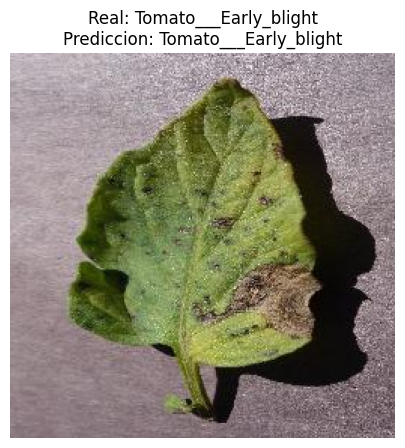

In [ ]:

# PASO: 12. PRIMERA INFERENCIA CON VIT

import matplotlib.pyplot as plt
import torch

# Seleccionar imagen de prueba
ejemplo = dataset_test[0]

imagen = ejemplo["image"].convert("RGB")
etiqueta_real = ejemplo["class_label"]

# Preparar imagen para ViT
entradas = procesador_vit(
    images=imagen,
    return_tensors="pt"
)

entradas = {
    clave: valor.to(device)
    for clave, valor in entradas.items()
}

# Ejecutar inferencia
with torch.inference_mode():
    salidas = modelo_vit(**entradas)

# Obtener prediccion
indice_predicho = salidas.logits.argmax(
    dim=-1
).item()

etiqueta_predicha = modelo_vit.config.id2label[
    indice_predicho
]

# Calcular confianza estimada
probabilidades = torch.softmax(
    salidas.logits, dim=-1
)

confianza = probabilidades.max().item() * 100

# Mostrar resultados
print("______________________________________________________")
print("\t\tPRIMERA PREDICCION VIT")
print("______________________________________________________")
print("Etiqueta real:", etiqueta_real)
print("Prediccion:", etiqueta_predicha)
print("Confianza estimada:", round(confianza, 2), "%")
print("Prediccion correcta:", etiqueta_real == etiqueta_predicha)

# Visualizar imagen
plt.figure(figsize=(6, 5))
plt.imshow(imagen)
plt.title(
    f"Real: {etiqueta_real}\n"
    f"Prediccion: {etiqueta_predicha}"
)
plt.axis("off")
plt.show()


In [ ]:
# PASO 13. EVALUACION COMPLETA DE VIT


import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Listas para almacenar resultados
etiquetas_reales = []
etiquetas_predichas = []
tiempos_inferencia = []

print("______________________________________________________")
print("\t\tEVALUACION VISION TRANSFORMER")
print("______________________________________________________")

# Calentamiento de GPU para estabilizar la medicion
imagen_inicial = dataset_test[0]["image"].convert("RGB")

entrada_inicial = procesador_vit(
    images=imagen_inicial,
    return_tensors="pt"
)

entrada_inicial = {
    k: v.to(device)
    for k, v in entrada_inicial.items()
}

with torch.inference_mode():
    for _ in range(10):
        _ = modelo_vit(**entrada_inicial)

if device.type == "cuda":
    torch.cuda.synchronize()

# Evaluar todas las imagenes
for i in range(len(dataset_test)):

    ejemplo = dataset_test[i]
    imagen = ejemplo["image"].convert("RGB")

    etiqueta_real = ejemplo["class_label"]

    entradas = procesador_vit(
        images=imagen,
        return_tensors="pt"
    )

    entradas = {
        k: v.to(device)
        for k, v in entradas.items()
    }

    # Sincronizar antes de medir
    if device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    with torch.inference_mode():
        salida = modelo_vit(**entradas)

    if device.type == "cuda":
        torch.cuda.synchronize()

    fin = time.perf_counter()

    indice = salida.logits.argmax(dim=-1).item()

    prediccion = modelo_vit.config.id2label[indice]

    etiquetas_reales.append(etiqueta_real)
    etiquetas_predichas.append(prediccion)

    tiempos_inferencia.append(
        (fin - inicio) * 1000
    )

    if (i + 1) % 100 == 0:
        print(
            f"Procesadas: {i + 1}/{len(dataset_test)}"
        )

# Calcular metricas
accuracy = accuracy_score(
    etiquetas_reales,
    etiquetas_predichas
)

precision = precision_score(
    etiquetas_reales,
    etiquetas_predichas,
    labels=clases_objetivo,
    average="macro",
    zero_division=0
)

recall = recall_score(
    etiquetas_reales,
    etiquetas_predichas,
    labels=clases_objetivo,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    etiquetas_reales,
    etiquetas_predichas,
    labels=clases_objetivo,
    average="macro",
    zero_division=0
)

latencia = np.mean(tiempos_inferencia)

# Mostrar resultados
print("______________________________________________________")
print("\t\tRESULTADOS VIT")
print("______________________________________________________")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision macro: {precision:.4f}")
print(f"Recall macro: {recall:.4f}")
print(f"F1-score macro: {f1:.4f}")
print(f"Latencia promedio: {latencia:.2f} ms")

print("______________________________________________________")
print("\t\tREPORTE POR CLASE")
print("______________________________________________________")

print(
    classification_report(
        etiquetas_reales,
        etiquetas_predichas,
        labels=clases_objetivo,
        zero_division=0
    )
)

# Guardar resultados para comparacion
resultados_vit = {
    "Modelo": "Vision Transformer",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Latencia (ms)": latencia,
    "Parametros": parametros
}

df_resultados_vit = pd.DataFrame(
    [resultados_vit]
)

display(df_resultados_vit)


______________________________________________________
		EVALUACION VISION TRANSFORMER
______________________________________________________
Procesadas: 100/908
Procesadas: 200/908
Procesadas: 300/908
Procesadas: 400/908
Procesadas: 500/908
Procesadas: 600/908
Procesadas: 700/908
Procesadas: 800/908
Procesadas: 900/908
______________________________________________________
		RESULTADOS VIT
______________________________________________________
Accuracy: 0.9989
Precision macro: 0.9990
Recall macro: 0.9991
F1-score macro: 0.9991
Latencia promedio: 13.61 ms
______________________________________________________
		REPORTE POR CLASE
______________________________________________________
                       precision    recall  f1-score   support

     Tomato___healthy       1.00      1.00      1.00       326
Tomato___Early_blight       1.00      1.00      1.00       200
 Tomato___Late_blight       1.00      1.00      1.00       382

             accuracy                           1.00  

,Modelo,Accuracy,Precision,Recall,F1-score,Latencia (ms),Parametros
0,Vision Transformer,0.998899,0.998981,0.999127,0.999053,13.609575,85827878


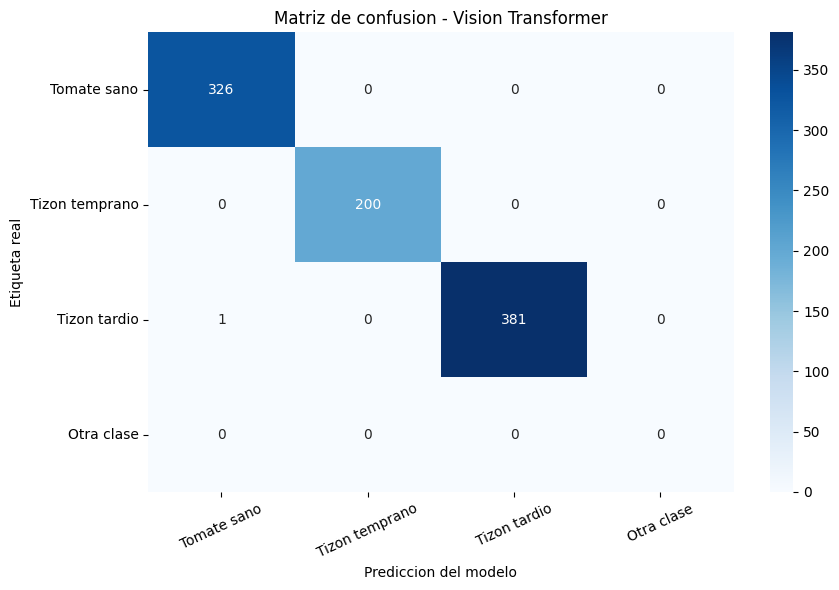

______________________________________________________
		ERRORES DE CLASIFICACION
______________________________________________________
Total de errores: 1

Imagen: 525
Real: Tomato___Late_blight
Prediccion: Tomato___healthy


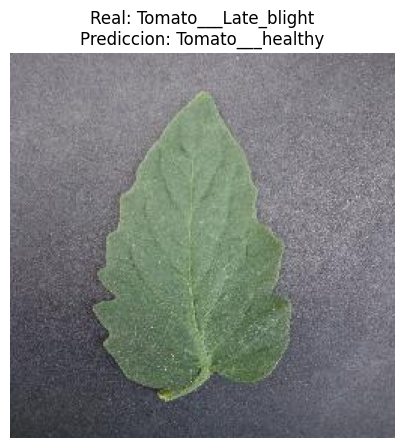

In [ ]:

# PASO: 14. MATRIZ DE CONFUSION VIT

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Etiquetas reales y predicciones
nombres_clases = [
    "Tomate sano",
    "Tizon temprano",
    "Tizon tardio",
    "Otra clase"
]

# Agrupar predicciones fuera de nuestras
# tres categorias como "Otra clase"
predicciones_agrupadas = [
    pred if pred in clases_objetivo else "Otra clase"
    for pred in etiquetas_predichas
]

etiquetas_matriz = clases_objetivo + ["Otra clase"]

matriz = confusion_matrix(
    etiquetas_reales,
    predicciones_agrupadas,
    labels=etiquetas_matriz
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases
)

plt.title("Matriz de confusion - Vision Transformer")
plt.xlabel("Prediccion del modelo")
plt.ylabel("Etiqueta real")
plt.xticks(rotation=25)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("______________________________________________________")
print("\t\tERRORES DE CLASIFICACION")
print("______________________________________________________")

errores = [
    i for i, (real, pred) in enumerate(
        zip(etiquetas_reales, etiquetas_predichas)
    )
    if real != pred
]

print("Total de errores:", len(errores))

for indice in errores:
    print("\nImagen:", indice)
    print("Real:", etiquetas_reales[indice])
    print("Prediccion:", etiquetas_predichas[indice])

    imagen_error = dataset_test[indice]["image"]

    plt.figure(figsize=(5, 5))
    plt.imshow(imagen_error)
    plt.title(
        f"Real: {etiquetas_reales[indice]}\n"
        f"Prediccion: {etiquetas_predichas[indice]}"
    )
    plt.axis("off")
    plt.show()


In [ ]:
# PASO 15: GUARDAR RESULTADOS DE VIT


import os
import pandas as pd

# Crear carpeta de resultados
os.makedirs("results", exist_ok=True)

# Guardar metricas
df_resultados_vit.to_csv(
    "results/metricas_vit.csv",
    index=False
)

# Guardar predicciones individuales
df_predicciones_vit = pd.DataFrame({
    "indice": range(len(etiquetas_reales)),
    "etiqueta_real": etiquetas_reales,
    "prediccion": etiquetas_predichas,
    "latencia_ms": tiempos_inferencia
})

df_predicciones_vit["correcta"] = (
    df_predicciones_vit["etiqueta_real"]
    == df_predicciones_vit["prediccion"]
)

df_predicciones_vit.to_csv(
    "results/predicciones_vit.csv",
    index=False
)
print("______________________________________________________")
print("\t\t RESULTADOS GUARDADOS")
print("______________________________________________________")
print("results/metricas_vit.csv")
print("results/predicciones_vit.csv")
print("Total:", len(df_predicciones_vit))
print("Errores:", (~df_predicciones_vit["correcta"]).sum())


______________________________________________________
		 RESULTADOS GUARDADOS
______________________________________________________
results/metricas_vit.csv
results/predicciones_vit.csv
Total: 908
Errores: 1


In [ ]:

# ==========================================
# 16. INSPECCION DE EFFICIENTNETV2-S
# ==========================================

from huggingface_hub import hf_hub_download
import json

repo_effnet = "BrandonFors/effnetv2_s_plant_disease"

print("______________________________________________________")
print("\t\tINSPECCION DE EFFICIENTNETV2-S")
print("______________________________________________________")

# Descargar configuracion
ruta_config = hf_hub_download(
    repo_id=repo_effnet,
    filename="config.json"
)

with open(ruta_config, "r", encoding="utf-8") as archivo:
    config_effnet = json.load(archivo)

print("______________________________________________________")
print("\t\tARQUITECTURA")
print("______________________________________________________")
print("Arquitecturas:", config_effnet.get("architectures"))
print("Tipo:", config_effnet.get("model_type"))
print("Auto map:", config_effnet.get("auto_map"))

print("______________________________________________________")
print("\t\tCONFIGURACIOM")
print("______________________________________________________")
for clave, valor in config_effnet.items():
    if clave not in ["id2label", "label2id"]:
        print(f"{clave}: {valor}")

print("______________________________________________________")
print("\t\tETIQUETAS")
print("______________________________________________________")
print("Total:", len(config_effnet.get("id2label", {})))

# Descargar README para revisar instrucciones
ruta_readme = hf_hub_download(
    repo_id=repo_effnet,
    filename="README.md"
)

with open(ruta_readme, "r", encoding="utf-8") as archivo:
    contenido = archivo.read()

print("______________________________________________________")
print("\t\tDOCUMENTACION DEL MODELO")
print("______________________________________________________")
print(contenido[:12000])


______________________________________________________
		INSPECCION DE EFFICIENTNETV2-S
______________________________________________________
______________________________________________________
		ARQUITECTURA
______________________________________________________
Arquitecturas: ['EffNetPlantDiseaseClassification']
Tipo: effnetv2_s_plant_disease
Auto map: None
______________________________________________________
		CONFIGURACIOM
______________________________________________________
architectures: ['EffNetPlantDiseaseClassification']
dropout_rate: 0.2
image_size: 384
model_type: effnetv2_s_plant_disease
num_classes: 38
torch_dtype: float32
transformers_version: 4.55.4
______________________________________________________
		ETIQUETAS
______________________________________________________
Total: 38
______________________________________________________
		DOCUMENTACION DEL MODELO
______________________________________________________
---
license: mit
datasets:
- BrandonFors/Plant-Dis

In [ ]:

# PASO 17. VERIFICAR CHECKPOINT EFFICIENTNETV2


import torch
import torchvision
from huggingface_hub import hf_hub_download
from safetensors import safe_open

print("______________________________________________________")
print("\t\tVERIFICACION EFFICIENTNETV2-S")
print("______________________________________________________")

repo_effnet = "BrandonFors/effnetv2_s_plant_disease"

# Descargar pesos en formato safetensors
ruta_pesos = hf_hub_download(
    repo_id=repo_effnet,
    filename="model.safetensors"
)

print("Checkpoint descargado:", ruta_pesos)

# Inspeccionar estructura sin cargar codigo remoto
with safe_open(ruta_pesos, framework="pt", device="cpu") as f:
    claves = list(f.keys())
print("______________________________________________________")
print("\t\tESTRUCTURA DE PESOS")
print("______________________________________________________")
print("Total de tensores:", len(claves))
print("Primeras 15 claves:")

for clave in claves[:15]:
    print(clave)

print("______________________________________________________")
print("\t\tCAPA DE CLASIFICACION")
print("______________________________________________________")
for clave in claves:
    if "classifier" in clave or "head" in clave:
        print(clave)


______________________________________________________
		VERIFICACION EFFICIENTNETV2-S
______________________________________________________
Checkpoint descargado: /root/.cache/huggingface/hub/models--BrandonFors--effnetv2_s_plant_disease/snapshots/79cd17f0dc04992aed5e888e69cac5b4531ac46f/model.safetensors
______________________________________________________
		ESTRUCTURA DE PESOS
______________________________________________________
Total de tensores: 782
Primeras 15 claves:
model.classifier.1.bias
model.classifier.1.weight
model.features.0.0.weight
model.features.0.1.bias
model.features.0.1.num_batches_tracked
model.features.0.1.running_mean
model.features.0.1.running_var
model.features.0.1.weight
model.features.1.0.block.0.0.weight
model.features.1.0.block.0.1.bias
model.features.1.0.block.0.1.num_batches_tracked
model.features.1.0.block.0.1.running_mean
model.features.1.0.block.0.1.running_var
model.features.1.0.block.0.1.weight
model.features.1.1.block.0.0.weight
______________

In [ ]:
# PASO 19: CARGA DEL MODELO EFFICIENTNETV2-S


import torch
import torchvision

from safetensors.torch import load_file

print("CARGANDO EFFICIENTNETV2-S")

# Crear arquitectura sin descargar pesos adicionales
modelo_effnet = torchvision.models.efficientnet_v2_s(
    weights=None
)

# Adaptar la capa de clasificacion a 38 clases
num_features = modelo_effnet.classifier[1].in_features

modelo_effnet.classifier[1] = torch.nn.Linear(
    num_features,
    38
)

# Cargar checkpoint
pesos_originales = load_file(ruta_pesos)

# Eliminar prefijo "model."
pesos_corregidos = {}

for clave, valor in pesos_originales.items():

    if clave.startswith("model."):
        nueva_clave = clave[len("model."):]
    else:
        nueva_clave = clave

    pesos_corregidos[nueva_clave] = valor

# Cargar todos los pesos
resultado = modelo_effnet.load_state_dict(
    pesos_corregidos,
    strict=True
)

print("Pesos cargados correctamente")
print(resultado)

# Enviar modelo a GPU
modelo_effnet = modelo_effnet.to(device)

# Activar modo evaluacion
modelo_effnet.eval()

# Contar parametros
parametros_effnet = sum(
    p.numel()
    for p in modelo_effnet.parameters()
)

print("\nINFORMACION DEL MODELO ")
print("Dispositivo:", next(modelo_effnet.parameters()).device)
print("Numero de clases:", 38)
print("Parametros:", f"{parametros_effnet:,}")


CARGANDO EFFICIENTNETV2-S
Pesos cargados correctamente
<All keys matched successfully>

INFORMACION DEL MODELO 
Dispositivo: cuda:0
Numero de clases: 38
Parametros: 20,226,166


PREPROCESAMIENTO EFFICIENTNETV2-S
ImageClassification(
    crop_size=[384]
    resize_size=[384]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

PRIMERA PREDICCION EFFICIENTNETV2-S
Etiqueta real: Tomato___Early_blight
Prediccion: Tomato___Early_blight
Confianza estimada: 99.95 %
Prediccion correcta: True


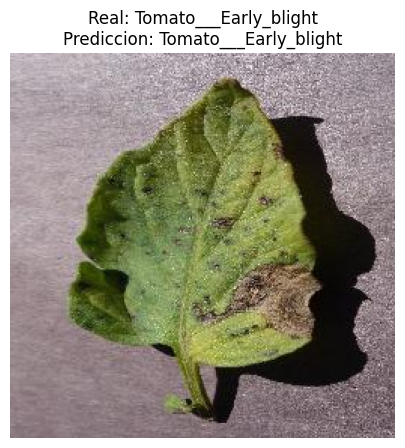

In [ ]:
# PASO 20. PRIMERA INFERENCIA EFFICIENTNETV2-S


import torch
import matplotlib.pyplot as plt

from torchvision.models import EfficientNet_V2_S_Weights

# Obtener transformaciones recomendadas
pesos_base = EfficientNet_V2_S_Weights.DEFAULT
transformacion_effnet = pesos_base.transforms()

print("PREPROCESAMIENTO EFFICIENTNETV2-S")
print(transformacion_effnet)

# Recuperar etiquetas desde config.json
id2label_effnet = {
    int(k): v
    for k, v in config_effnet["id2label"].items()
}

# Seleccionar la misma primera imagen
# que utilizamos con ViT
ejemplo = dataset_test[0]

imagen = ejemplo["image"].convert("RGB")
etiqueta_real = ejemplo["class_label"]

# Aplicar transformaciones
entrada = transformacion_effnet(imagen)

# Agregar dimension de lote
entrada = entrada.unsqueeze(0).to(device)

# Inferencia
with torch.inference_mode():
    salida = modelo_effnet(entrada)

# Obtener clase predicha
indice_predicho = salida.argmax(dim=1).item()

etiqueta_predicha = id2label_effnet[indice_predicho]

# Confianza softmax
probabilidades = torch.softmax(salida, dim=1)
confianza = probabilidades.max().item() * 100

print("\nPRIMERA PREDICCION EFFICIENTNETV2-S")
print("Etiqueta real:", etiqueta_real)
print("Prediccion:", etiqueta_predicha)
print("Confianza estimada:", round(confianza, 2), "%")
print("Prediccion correcta:", etiqueta_real == etiqueta_predicha)

# Mostrar imagen
plt.figure(figsize=(6, 5))
plt.imshow(imagen)
plt.title(
    f"Real: {etiqueta_real}\n"
    f"Prediccion: {etiqueta_predicha}"
)
plt.axis("off")
plt.show()


In [ ]:
# PASO 21: EVALUACION COMPLETA EFFICIENTNETV2-S


import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Activar modo evaluacion
modelo_effnet.eval()

# Almacenar resultados
reales_effnet = []
predicciones_effnet = []
tiempos_effnet = []

print("EVALUACION EFFICIENTNETV2-S")

# Calentamiento de GPU
imagen_inicial = dataset_test[0]["image"].convert("RGB")

entrada_inicial = (
    transformacion_effnet(imagen_inicial)
    .unsqueeze(0)
    .to(device)
)

with torch.inference_mode():
    for _ in range(10):
        _ = modelo_effnet(entrada_inicial)

if device.type == "cuda":
    torch.cuda.synchronize()

# Evaluar todas las imagenes
for i in range(len(dataset_test)):

    ejemplo = dataset_test[i]
    imagen = ejemplo["image"].convert("RGB")

    etiqueta_real = ejemplo["class_label"]

    # Preprocesamiento fuera de la medicion
    entrada = (
        transformacion_effnet(imagen)
        .unsqueeze(0)
        .to(device)
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    with torch.inference_mode():
        salida = modelo_effnet(entrada)

    if device.type == "cuda":
        torch.cuda.synchronize()

    fin = time.perf_counter()

    indice = salida.argmax(dim=1).item()
    prediccion = id2label_effnet[indice]

    reales_effnet.append(etiqueta_real)
    predicciones_effnet.append(prediccion)

    tiempos_effnet.append(
        (fin - inicio) * 1000
    )

    if (i + 1) % 100 == 0:
        print(
            f"Procesadas: {i + 1}/{len(dataset_test)}"
        )

# Calcular metricas
accuracy_effnet = accuracy_score(
    reales_effnet,
    predicciones_effnet
)

precision_effnet = precision_score(
    reales_effnet,
    predicciones_effnet,
    labels=clases_objetivo,
    average="macro",
    zero_division=0
)

recall_effnet = recall_score(
    reales_effnet,
    predicciones_effnet,
    labels=clases_objetivo,
    average="macro",
    zero_division=0
)

f1_effnet = f1_score(
    reales_effnet,
    predicciones_effnet,
    labels=clases_objetivo,
    average="macro",
    zero_division=0
)

latencia_effnet = np.mean(tiempos_effnet)

print("\nRESULTADOS EFFICIENTNETV2-S")
print(f"Accuracy: {accuracy_effnet:.4f}")
print(f"Precision macro: {precision_effnet:.4f}")
print(f"Recall macro: {recall_effnet:.4f}")
print(f"F1-score macro: {f1_effnet:.4f}")
print(f"Latencia promedio: {latencia_effnet:.2f} ms")

print("\nREPORTE POR CLASE")

print(
    classification_report(
        reales_effnet,
        predicciones_effnet,
        labels=clases_objetivo,
        zero_division=0
    )
)

# Guardar metricas
resultados_effnet = {
    "Modelo": "EfficientNetV2-S",
    "Accuracy": accuracy_effnet,
    "Precision": precision_effnet,
    "Recall": recall_effnet,
    "F1-score": f1_effnet,
    "Latencia (ms)": latencia_effnet,
    "Parametros": parametros_effnet
}

df_resultados_effnet = pd.DataFrame(
    [resultados_effnet]
)

print("\nTABLA DE RESULTADOS ")
display(df_resultados_effnet)


EVALUACION EFFICIENTNETV2-S
Procesadas: 100/908
Procesadas: 200/908
Procesadas: 300/908
Procesadas: 400/908
Procesadas: 500/908
Procesadas: 600/908
Procesadas: 700/908
Procesadas: 800/908
Procesadas: 900/908

RESULTADOS EFFICIENTNETV2-S
Accuracy: 0.9989
Precision macro: 0.9990
Recall macro: 0.9991
F1-score macro: 0.9991
Latencia promedio: 26.18 ms

REPORTE POR CLASE
                       precision    recall  f1-score   support

     Tomato___healthy       1.00      1.00      1.00       326
Tomato___Early_blight       1.00      1.00      1.00       200
 Tomato___Late_blight       1.00      1.00      1.00       382

             accuracy                           1.00       908
            macro avg       1.00      1.00      1.00       908
         weighted avg       1.00      1.00      1.00       908


TABLA DE RESULTADOS 


,Modelo,Accuracy,Precision,Recall,F1-score,Latencia (ms),Parametros
0,EfficientNetV2-S,0.998899,0.998981,0.999127,0.999053,26.181789,20226166


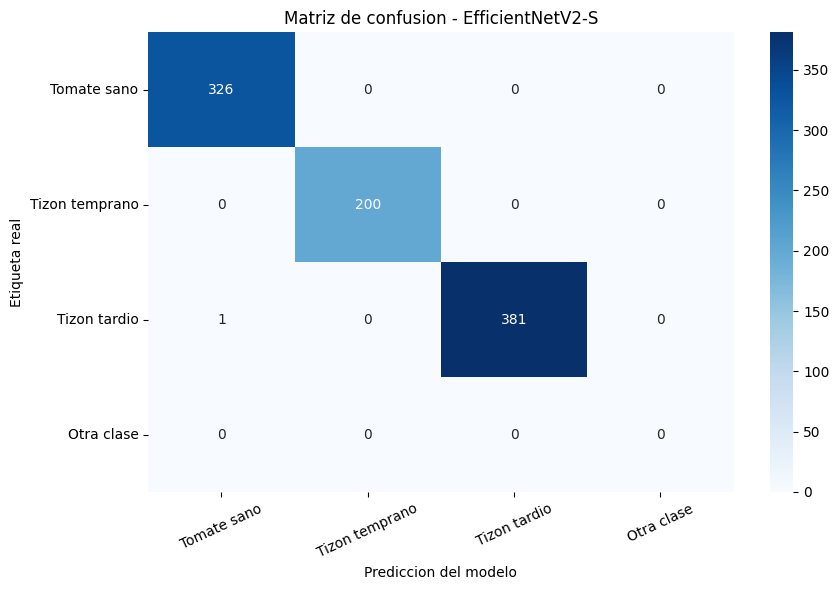


ERRORES EFFICIENTNETV2-S
Total de errores: 1

Imagen: 525
Real: Tomato___Late_blight
Prediccion: Tomato___healthy


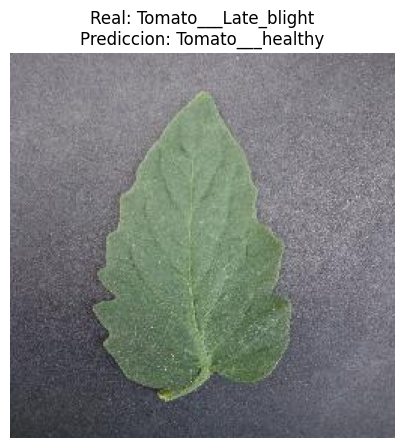


COMPARACION DE ERRORES
Errores ViT: [525]
Errores EfficientNet: [525]
Errores compartidos: [525]


In [ ]:

# PASO 22. MATRIZ DE CONFUSION EFFICIENTNETV2-S


import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Etiquetas de las tres enfermedades
nombres_clases = [
    "Tomate sano",
    "Tizon temprano",
    "Tizon tardio",
    "Otra clase"
]

etiquetas_matriz = clases_objetivo + ["Otra clase"]

# Agrupar predicciones fuera de las 3 clases
predicciones_agrupadas_effnet = [
    pred if pred in clases_objetivo else "Otra clase"
    for pred in predicciones_effnet
]

matriz_effnet = confusion_matrix(
    reales_effnet,
    predicciones_agrupadas_effnet,
    labels=etiquetas_matriz
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    matriz_effnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases
)

plt.title("Matriz de confusion - EfficientNetV2-S")
plt.xlabel("Prediccion del modelo")
plt.ylabel("Etiqueta real")
plt.xticks(rotation=25)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Identificar errores
errores_effnet = [
    i for i, (real, pred) in enumerate(
        zip(reales_effnet, predicciones_effnet)
    )
    if real != pred
]

print("\nERRORES EFFICIENTNETV2-S")
print("Total de errores:", len(errores_effnet))

for indice in errores_effnet:

    print("\nImagen:", indice)
    print("Real:", reales_effnet[indice])
    print("Prediccion:", predicciones_effnet[indice])

    imagen = dataset_test[indice]["image"]

    plt.figure(figsize=(5, 5))
    plt.imshow(imagen)
    plt.title(
        f"Real: {reales_effnet[indice]}\n"
        f"Prediccion: {predicciones_effnet[indice]}"
    )
    plt.axis("off")
    plt.show()

# Comparar errores entre ambos modelos
print("\nCOMPARACION DE ERRORES")

errores_vit_set = set(errores)
errores_effnet_set = set(errores_effnet)

print("Errores ViT:", sorted(errores_vit_set))
print("Errores EfficientNet:", sorted(errores_effnet_set))

print(
    "Errores compartidos:",
    sorted(errores_vit_set & errores_effnet_set)
)


In [ ]:
# PASO 23. GUARDAR RESULTADOS EFFICIENTNETV2-S

import os
import pandas as pd

os.makedirs("results", exist_ok=True)

# Guardar metricas
df_resultados_effnet.to_csv(
    "results/metricas_effnet.csv",
    index=False
)

# Guardar predicciones individuales
df_predicciones_effnet = pd.DataFrame({
    "indice": range(len(reales_effnet)),
    "etiqueta_real": reales_effnet,
    "prediccion": predicciones_effnet,
    "latencia_ms": tiempos_effnet
})

df_predicciones_effnet["correcta"] = (
    df_predicciones_effnet["etiqueta_real"]
    == df_predicciones_effnet["prediccion"]
)

df_predicciones_effnet.to_csv(
    "results/predicciones_effnet.csv",
    index=False
)

print("RESULTADOS GUARDADOS")
print("results/metricas_effnet.csv")
print("results/predicciones_effnet.csv")
print("Total:", len(df_predicciones_effnet))
print("Errores:", (~df_predicciones_effnet["correcta"]).sum())


RESULTADOS GUARDADOS
results/metricas_effnet.csv
results/predicciones_effnet.csv
Total: 908
Errores: 1


In [ ]:
# PASO 24: INSPECCION DEL MODELO RESNET-50


from huggingface_hub import hf_hub_download
import json

repo_resnet = "raysarocha/plant-resnet50-38classes"

print("INSPECCION RESNET-50")

# Descargar configuracion
ruta_config_resnet = hf_hub_download(
    repo_id=repo_resnet,
    filename="config.json"
)

with open(
    ruta_config_resnet,
    "r",
    encoding="utf-8"
) as archivo:
    config_resnet = json.load(archivo)

print("\nCONFIGURACION")

for clave, valor in config_resnet.items():

    if clave not in ["id2label", "label2id"]:
        print(f"{clave}: {valor}")

print("\nETIQUETAS")
print(
    "Total:",
    len(config_resnet.get("id2label", {}))
)

# Descargar documentacion
ruta_readme_resnet = hf_hub_download(
    repo_id=repo_resnet,
    filename="README.md"
)

with open(
    ruta_readme_resnet,
    "r",
    encoding="utf-8"
) as archivo:
    readme_resnet = archivo.read()

print("\n DOCUMENTACION RESNET-50 ")
print(readme_resnet[:15000])


INSPECCION RESNET-50

CONFIGURACION
framework: tf-keras
image_size: 224
rescale: 0.00392156862745098
mean: None
std: None
num_classes: 38
architecture: ResNet50
task: image-classification

ETIQUETAS
Total: 38

 DOCUMENTACION RESNET-50 
---
tags:
- plants
- plant-disease
- image-classification
- tensorflow
- keras
- resnet50
license: apache-2.0
pipeline_tag: image-classification
---

# plant-resnet50-38classes

Modelo keras (tensorflow) para reconhecimento de plantas e doenças (38 classes).

## 📋 Classes suportadas

O modelo identifica as seguintes plantas e condições:

- **Maçã**: sarna, podridão negra, ferrugem do cedro, saudável
- **Mirtilo**: saudável
- **Cereja**: oídio, saudável
- **Milho**: mancha de cercospora, ferrugem comum, queima das folhas, saudável
- **Uva**: podridão negra, esca, queima das folhas, saudável
- **Laranja**: citrus greening
- **Pêssego**: mancha bacteriana, saudável
- **Pimentão**: mancha bacteriana, saudável
- **Batata**: requeima precoce, requeima tardia, 

In [ ]:
# 26. VERIFICACION TENSORFLOW Y KERAS


import importlib.metadata as metadata

print("VERIFICACION DEL ENTORNO")

for paquete in ["tensorflow", "keras", "tf-keras"]:
    try:
        print(paquete, metadata.version(paquete))
    except metadata.PackageNotFoundError:
        print(paquete, "NO INSTALADO")

try:
    import tensorflow as tf

    print("\nTENSORFLOW")
    print("Version:", tf.__version__)

    gpus = tf.config.list_physical_devices("GPU")

    print("GPU disponibles:", gpus)

    if gpus:
        print("TensorFlow detecta GPU")
    else:
        print("TensorFlow utilizara CPU")

except Exception as error:
    print("\nError al importar TensorFlow:")
    print(type(error).__name__, str(error))


VERIFICACION DEL ENTORNO
tensorflow 2.21.0
keras 3.13.2
tf-keras 2.21.0

TENSORFLOW
Version: 2.21.0
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow detecta GPU


In [ ]:
# 26. LIBERAR MEMORIA GPU


import gc
import torch

print("LIBERANDO MEMORIA PYTORCH ")

# Eliminar modelos anteriores de la memoria
for nombre in ["modelo_vit", "modelo_effnet"]:
    if nombre in globals():
        del globals()[nombre]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

    print(
        "Memoria PyTorch reservada:",
        round(torch.cuda.memory_reserved() / 1024**3, 2),
        "GB"
    )

print("Limpieza finalizada")


LIBERANDO MEMORIA PYTORCH 
Memoria PyTorch reservada: 0.04 GB
Limpieza finalizada


In [ ]:
# 27. CARGA DEL MODELO RESNET-50


import tensorflow as tf
import numpy as np
from huggingface_hub import hf_hub_download

print("CARGANDO RESNET-50")

# Configurar crecimiento dinamico de memoria
try:
    gpus = tf.config.list_physical_devices("GPU")

    for gpu in gpus:
        tf.config.experimental.set_memory_growth(
            gpu, True
        )

    print("Configuracion de memoria GPU aplicada")

except RuntimeError as error:
    print("GPU ya inicializada:", error)

# Descargar el modelo
ruta_modelo_resnet = hf_hub_download(
    repo_id=repo_resnet,
    filename="model.keras"
)

print("Modelo descargado")

# Cargar modelo Keras
modelo_resnet = tf.keras.models.load_model(
    ruta_modelo_resnet,
    compile=False,
    safe_mode=True
)

print("\nMDELO CARGADO")
print("Nombre:", modelo_resnet.name)
print("Entrada:", modelo_resnet.input_shape)
print("Salida:", modelo_resnet.output_shape)

# Contar parametros
parametros_resnet = modelo_resnet.count_params()

print("Parametros:", f"{parametros_resnet:,}")

# Mostrar informacion de la ultima capa
ultima_capa = modelo_resnet.layers[-1]

print("\nULTIMA CAPA")
print("Nombre:", ultima_capa.name)
print("Tipo:", type(ultima_capa).__name__)

if hasattr(ultima_capa, "activation"):
    print(
        "Activacion:",
        ultima_capa.activation.__name__
    )


CARGANDO RESNET-50
Configuracion de memoria GPU aplicada


model.keras: reconstructing file:   0%|          |  0.00B /  109MB            

model.keras: downloading bytes:           |  0.00B            

Modelo descargado

MDELO CARGADO
Nombre: ResNet50_PlantVillage_38Classes
Entrada: (None, 224, 224, 3)
Salida: (None, 38)
Parametros: 24,788,134

ULTIMA CAPA
Nombre: output
Tipo: Dense
Activacion: softmax


PRIMERA PREDICCION RESNET-50 

 RESULTADOS 
Etiqueta real: Tomato___Early_blight
Prediccion: Squash___Powdery_mildew
Confianza estimada: 32.1 %
Prediccion correcta: False


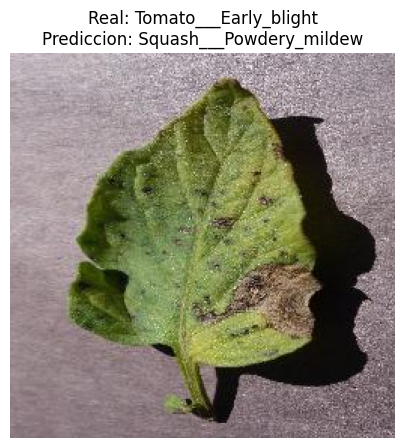

In [ ]:
# PASO 28. PRIMERA INFERENCIA RESNET-50

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("PRIMERA PREDICCION RESNET-50 ")

# Recuperar etiquetas desde la configuracion
id2label_resnet = {
    int(k): v
    for k, v in config_resnet["id2label"].items()
}

# Seleccionar la misma imagen de prueba
ejemplo = dataset_test[0]

imagen = ejemplo["image"].convert("RGB")
etiqueta_real = ejemplo["class_label"]

# Preprocesamiento segun el autor
imagen_procesada = imagen.resize(
    (224, 224)
)

entrada = np.asarray(
    imagen_procesada,
    dtype=np.float32
)

# Normalizar pixeles a [0, 1]
entrada = entrada * config_resnet["rescale"]

# Agregar dimension de lote
entrada = np.expand_dims(entrada, axis=0)

# Ejecutar inferencia
salida = modelo_resnet(
    tf.convert_to_tensor(entrada),
    training=False
)

# Convertir resultado a NumPy
probabilidades = salida.numpy()[0]

# No aplicar softmax nuevamente
indice_predicho = int(
    np.argmax(probabilidades)
)

etiqueta_predicha = id2label_resnet[
    indice_predicho
]

confianza = float(
    probabilidades[indice_predicho] * 100
)

print("\n RESULTADOS ")
print("Etiqueta real:", etiqueta_real)
print("Prediccion:", etiqueta_predicha)
print("Confianza estimada:", round(confianza, 2), "%")
print("Prediccion correcta:", etiqueta_real == etiqueta_predicha)

# Visualizar imagen
plt.figure(figsize=(6, 5))
plt.imshow(imagen)

plt.title(
    f"Real: {etiqueta_real}\n"
    f"Prediccion: {etiqueta_predicha}"
)

plt.axis("off")
plt.show()


In [ ]:
# PASO 29. DIAGNOSTICO DE RESNET-50


import numpy as np
import tensorflow as tf

print("DIAGNOSTICO RESNET-50")

ejemplo = dataset_test[0]
imagen = ejemplo["image"].convert("RGB")

imagen_224 = imagen.resize((224, 224))

arr = np.asarray(
    imagen_224,
    dtype=np.float32
)

# Metodo A: preprocesamiento documentado
entrada_a = np.expand_dims(
    arr / 255.0,
    axis=0
)

# Metodo B: preprocesamiento estandar ResNet50
entrada_b = np.expand_dims(
    tf.keras.applications.resnet50.preprocess_input(
        arr.copy()
    ),
    axis=0
)

def evaluar_preprocesamiento(entrada, nombre):

    salida = modelo_resnet(
        tf.convert_to_tensor(entrada),
        training=False
    ).numpy()[0]

    print("\n" + "_" * 50)
    print(nombre)

    print("Suma probabilidades:", salida.sum())
    print("Minimo:", salida.min())
    print("Maximo:", salida.max())

    indices = np.argsort(salida)[-5:][::-1]

    print("\nTOP 5 PREDICCIONES")

    for indice in indices:
        print(
            id2label_resnet[int(indice)],
            ":",
            round(float(salida[indice]) * 100, 2),
            "%"
        )

evaluar_preprocesamiento(
    entrada_a,
    "A. NORMALIZACION DOCUMENTADA /255"
)

evaluar_preprocesamiento(
    entrada_b,
    "B. PREPROCESAMIENTO ESTANDAR RESNET50"
)


DIAGNOSTICO RESNET-50

__________________________________________________
A. NORMALIZACION DOCUMENTADA /255
Suma probabilidades: 0.99999994
Minimo: 3.457949e-05
Maximo: 0.3210383

TOP 5 PREDICCIONES
Squash___Powdery_mildew : 32.1 %
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 16.63 %
Corn_(maize)___Common_rust_ : 13.62 %
Tomato___Spider_mites Two-spotted_spider_mite : 9.71 %
Soybean___healthy : 6.77 %

__________________________________________________
B. PREPROCESAMIENTO ESTANDAR RESNET50
Suma probabilidades: 1.0
Minimo: 0.0
Maximo: 1.0

TOP 5 PREDICCIONES
Blueberry___healthy : 100.0 %
Tomato___healthy : 0.0 %
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 0.0 %
Tomato___Target_Spot : 0.0 %
Tomato___Spider_mites Two-spotted_spider_mite : 0.0 %


In [ ]:

# 30. DIAGNOSTICO MULTICLASE RESNET-50

import numpy as np
import pandas as pd
import tensorflow as tf

print(" DIAGNOSTICO MULTICLASE RESNET-50 ")

# Seleccionar una imagen de cada clase disponible
dataset_completo = dataset["train"]

clases_disponibles = sorted(
    set(dataset_completo["class_label"])
)

resultados_diagnostico = []

for clase in clases_disponibles:

    # Buscar primera imagen de la clase
    indice = next(
        i for i, etiqueta in enumerate(
            dataset_completo["class_label"]
        )
        if etiqueta == clase
    )

    ejemplo = dataset_completo[indice]

    imagen = ejemplo["image"].convert("RGB")
    imagen = imagen.resize((224, 224))

    entrada = np.asarray(
        imagen,
        dtype=np.float32
    ) / 255.0

    entrada = np.expand_dims(entrada, axis=0)

    salida = modelo_resnet(
        tf.convert_to_tensor(entrada),
        training=False
    ).numpy()[0]

    indice_predicho = int(np.argmax(salida))

    prediccion = id2label_resnet[indice_predicho]

    resultados_diagnostico.append({
        "Real": clase,
        "Prediccion": prediccion,
        "Indice predicho": indice_predicho,
        "Confianza": float(salida[indice_predicho]),
        "Correcta": clase == prediccion
    })

df_diagnostico = pd.DataFrame(
    resultados_diagnostico
)

print("\nRESULTADOS POR CLASE")
display(df_diagnostico)

print("\nRESUMEN")
print("Clases evaluadas:", len(df_diagnostico))
print("Aciertos:", df_diagnostico["Correcta"].sum())

print("\nCLASES MAS PREDICHAS")
print(
    df_diagnostico["Prediccion"].value_counts().head(10)
)


 DIAGNOSTICO MULTICLASE RESNET-50 

RESULTADOS POR CLASE


,Real,Prediccion,Indice predicho,Confianza,Correcta
0,Apple___Apple_scab,Apple___Apple_scab,0,0.694607,True
1,Apple___Black_rot,Soybean___healthy,24,0.688456,False
2,Apple___Cedar_apple_rust,Blueberry___healthy,4,0.301105,False
3,Apple___healthy,Apple___healthy,3,0.987870,True
4,Blueberry___healthy,Blueberry___healthy,4,0.942089,True
5,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour)___Powdery_mildew,5,0.832481,True
6,Cherry_(including_sour)___healthy,Apple___healthy,3,0.776439,False
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,9,0.880448,False
8,Corn_(maize)___Common_rust_,Corn_(maize)___Common_rust_,8,0.997709,True
9,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Northern_Leaf_Blight,9,0.991191,True



RESUMEN
Clases evaluadas: 38
Aciertos: 23

CLASES MAS PREDICHAS
Prediccion
Soybean___healthy                             6
Apple___healthy                               5
Blueberry___healthy                           2
Corn_(maize)___Northern_Leaf_Blight           2
Raspberry___healthy                           2
Squash___Powdery_mildew                       2
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)    2
Apple___Apple_scab                            1
Corn_(maize)___healthy                        1
Corn_(maize)___Common_rust_                   1
Name: count, dtype: int64


In [ ]:
# PASO 31. EVALUACION COMPLETA RESNET-50


import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("EVALUACION RESNET-50")

reales_resnet = []
predicciones_resnet = []
tiempos_resnet = []

# Preparar una imagen para calentamiento
imagen_inicial = dataset_test[0]["image"].convert("RGB")
imagen_inicial = imagen_inicial.resize((224, 224))

entrada_inicial = np.asarray(
    imagen_inicial,
    dtype=np.float32
) / 255.0

entrada_inicial = tf.convert_to_tensor(
    entrada_inicial[np.newaxis, ...]
)

# Funcion compilada para inferencia
@tf.function
def inferencia_resnet(entrada):
    return modelo_resnet(entrada, training=False)

# Calentamiento
for _ in range(10):
    salida = inferencia_resnet(entrada_inicial)
    _ = salida.numpy()

# Evaluacion
for i in range(len(dataset_test)):

    ejemplo = dataset_test[i]

    imagen = ejemplo["image"].convert("RGB")
    etiqueta_real = ejemplo["class_label"]

    # Preprocesamiento
    imagen = imagen.resize((224, 224))

    entrada = np.asarray(
        imagen,
        dtype=np.float32
    ) / 255.0

    entrada = tf.convert_to_tensor(
        entrada[np.newaxis, ...]
    )

    # Medicion de inferencia
    inicio = time.perf_counter()

    salida = inferencia_resnet(entrada)

    # .numpy() sincroniza la salida
    probabilidades = salida.numpy()[0]

    fin = time.perf_counter()

    indice = int(np.argmax(probabilidades))
    prediccion = id2label_resnet[indice]

    reales_resnet.append(etiqueta_real)
    predicciones_resnet.append(prediccion)

    tiempos_resnet.append(
        (fin - inicio) * 1000
    )

    if (i + 1) % 100 == 0:
        print(
            f"Procesadas: {i + 1}/{len(dataset_test)}"
        )

# Calcular metricas
accuracy_resnet = accuracy_score(
    reales_resnet,
    predicciones_resnet
)

precision_resnet = precision_score(
    reales_resnet,
    predicciones_resnet,
    labels=clases_objetivo,
    average="macro",
    zero_division=0
)

recall_resnet = recall_score(
    reales_resnet,
    predicciones_resnet,
    labels=clases_objetivo,
    average="macro",
    zero_division=0
)

f1_resnet = f1_score(
    reales_resnet,
    predicciones_resnet,
    labels=clases_objetivo,
    average="macro",
    zero_division=0
)

latencia_resnet = np.mean(tiempos_resnet)

print("\n RESULTADOS RESNET-50")
print(f"Accuracy: {accuracy_resnet:.4f}")
print(f"Precision macro: {precision_resnet:.4f}")
print(f"Recall macro: {recall_resnet:.4f}")
print(f"F1-score macro: {f1_resnet:.4f}")
print(f"Latencia promedio: {latencia_resnet:.2f} ms")

print("\nREPORTE POR CLASE")

print(
    classification_report(
        reales_resnet,
        predicciones_resnet,
        labels=clases_objetivo,
        zero_division=0
    )
)

# Crear tabla de resultados
resultados_resnet = {
    "Modelo": "ResNet-50",
    "Accuracy": accuracy_resnet,
    "Precision": precision_resnet,
    "Recall": recall_resnet,
    "F1-score": f1_resnet,
    "Latencia (ms)": latencia_resnet,
    "Parametros": parametros_resnet
}

df_resultados_resnet = pd.DataFrame(
    [resultados_resnet]
)

display(df_resultados_resnet)


EVALUACION RESNET-50
Procesadas: 100/908
Procesadas: 200/908
Procesadas: 300/908
Procesadas: 400/908
Procesadas: 500/908
Procesadas: 600/908
Procesadas: 700/908
Procesadas: 800/908
Procesadas: 900/908

 RESULTADOS RESNET-50
Accuracy: 0.3293
Precision macro: 0.6408
Recall macro: 0.2958
F1-score macro: 0.3824
Latencia promedio: 15.15 ms

REPORTE POR CLASE
                       precision    recall  f1-score   support

     Tomato___healthy       0.00      0.00      0.00       326
Tomato___Early_blight       0.96      0.22      0.36       200
 Tomato___Late_blight       0.97      0.67      0.79       382

            micro avg       0.96      0.33      0.49       908
            macro avg       0.64      0.30      0.38       908
         weighted avg       0.62      0.33      0.41       908



,Modelo,Accuracy,Precision,Recall,F1-score,Latencia (ms),Parametros
0,ResNet-50,0.329295,0.64081,0.295846,0.382399,15.146453,24788134


MATRIZ DE CONFUSION RESNET-50


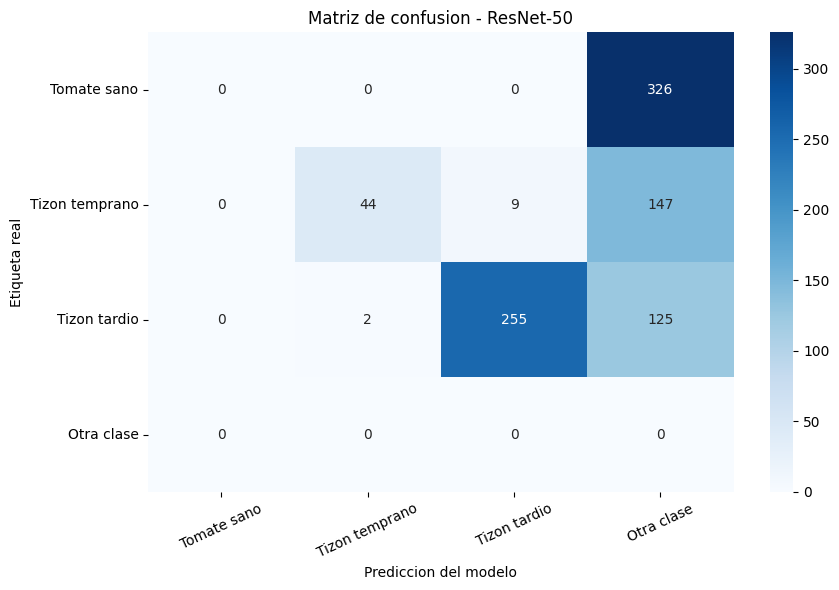


RESUMEN DE ERRORES
Total de imagenes: 908
Predicciones correctas: 299
Predicciones incorrectas: 609

CLASES MAS PREDICHAS
Tomato___Late_blight                             264
Apple___healthy                                  167
Squash___Powdery_mildew                          132
Tomato___Spider_mites Two-spotted_spider_mite    100
Soybean___healthy                                 89
Tomato___Leaf_Mold                                51
Tomato___Early_blight                             46
Corn_(maize)___Northern_Leaf_Blight               16
Strawberry___Leaf_scorch                          10
Potato___Late_blight                               9
Potato___Early_blight                              5
Corn_(maize)___Common_rust_                        3
Raspberry___healthy                                3
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)         3
Corn_(maize)___healthy                             3
Name: count, dtype: int64


In [ ]:
# PASO 32. MATRIZ DE CONFUSION RESNET-50

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

print("MATRIZ DE CONFUSION RESNET-50")

# Mantener las mismas etiquetas que usamos
# en ViT y EfficientNetV2-S
etiquetas_matriz = clases_objetivo + ["Otra clase"]

nombres_clases = [
    "Tomate sano",
    "Tizon temprano",
    "Tizon tardio",
    "Otra clase"
]

# Agrupar predicciones externas
predicciones_agrupadas_resnet = [
    pred if pred in clases_objetivo else "Otra clase"
    for pred in predicciones_resnet
]

matriz_resnet = confusion_matrix(
    reales_resnet,
    predicciones_agrupadas_resnet,
    labels=etiquetas_matriz
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    matriz_resnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases
)

plt.title("Matriz de confusion - ResNet-50")
plt.xlabel("Prediccion del modelo")
plt.ylabel("Etiqueta real")
plt.xticks(rotation=25)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Resumen de errores
errores_resnet = [
    i for i, (real, pred) in enumerate(
        zip(reales_resnet, predicciones_resnet)
    )
    if real != pred
]

print("\nRESUMEN DE ERRORES")
print("Total de imagenes:", len(reales_resnet))
print("Predicciones correctas:",
      len(reales_resnet) - len(errores_resnet))
print("Predicciones incorrectas:", len(errores_resnet))

print("\nCLASES MAS PREDICHAS")
print(
    pd.Series(predicciones_resnet)
    .value_counts()
    .head(15)
)


In [ ]:

# PASO 33: GUARDAR RESULTADOS RESNET-50


import os
import pandas as pd

os.makedirs("results", exist_ok=True)

# Guardar metricas
df_resultados_resnet.to_csv(
    "results/metricas_resnet.csv",
    index=False
)

# Guardar predicciones
df_predicciones_resnet = pd.DataFrame({
    "indice": range(len(reales_resnet)),
    "etiqueta_real": reales_resnet,
    "prediccion": predicciones_resnet,
    "latencia_ms": tiempos_resnet
})

df_predicciones_resnet["correcta"] = (
    df_predicciones_resnet["etiqueta_real"]
    == df_predicciones_resnet["prediccion"]
)

df_predicciones_resnet.to_csv(
    "results/predicciones_resnet.csv",
    index=False
)

print("RESULTADOS GUARDADOS")
print("results/metricas_resnet.csv")
print("results/predicciones_resnet.csv")
print("Total:", len(df_predicciones_resnet))
print(
    "Errores:",
    (~df_predicciones_resnet["correcta"]).sum()
)


RESULTADOS GUARDADOS
results/metricas_resnet.csv
results/predicciones_resnet.csv
Total: 908
Errores: 609


In [ ]:
# PASO 35. COMPARACION FINAL DE LOS TRES MODELOS


import pandas as pd
import os

print("=== COMPARACION DE MODELOS ===")

# Cargar resultados previamente guardados
vit = pd.read_csv("results/metricas_vit.csv")
effnet = pd.read_csv("results/metricas_effnet.csv")
resnet = pd.read_csv("results/metricas_resnet.csv")

# Unificar resultados
comparacion = pd.concat(
    [vit, effnet, resnet],
    ignore_index=True
)

# Ordenar por F1-score
comparacion = comparacion.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

# Guardar comparacion
comparacion.to_csv(
    "results/comparacion_modelos.csv",
    index=False
)

print("\nRESULTADOS CONSOLIDADOS")
display(comparacion.round(4))

print("\nArchivo guardado:")
print("results/comparacion_modelos.csv")


=== COMPARACION DE MODELOS ===

RESULTADOS CONSOLIDADOS


,Modelo,Accuracy,Precision,Recall,F1-score,Latencia (ms),Parametros
0,Vision Transformer,0.9989,0.9990,0.9991,0.9991,13.6096,85827878
1,EfficientNetV2-S,0.9989,0.9990,0.9991,0.9991,26.1818,20226166
2,ResNet-50,0.3293,0.6408,0.2958,0.3824,15.1465,24788134



Archivo guardado:
results/comparacion_modelos.csv


ANALISIS DE EFICIENCIA

TABLA DE EFICIENCIA


,Modelo,Accuracy,F1-score,Latencia (ms),Parametros (M),Memoria pesos FP32 (MB),Imagenes/segundo
0,Vision Transformer,0.999,0.999,13.610,85.828,327.407,73.478
1,EfficientNetV2-S,0.999,0.999,26.182,20.226,77.157,38.194
2,ResNet-50,0.329,0.382,15.146,24.788,94.559,66.022


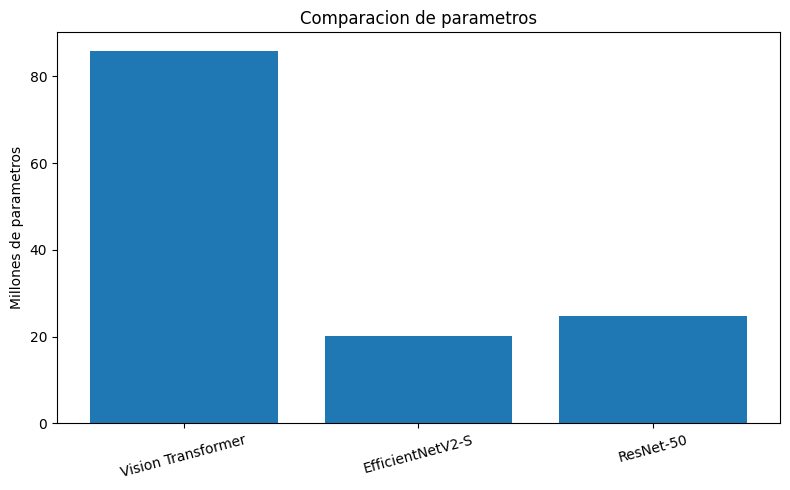

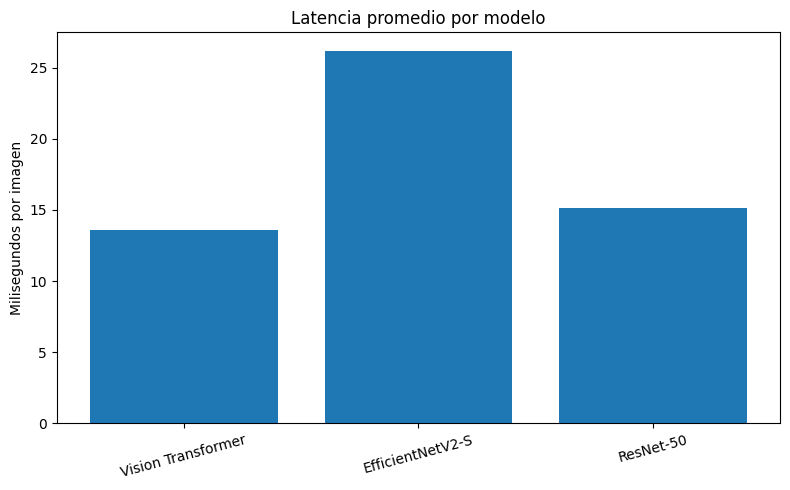


Archivo guardado:
results/analisis_eficiencia.csv


In [ ]:
# PASO 35. ANALISIS DE EFICIENCIA Y TRADE-OFFS

import pandas as pd
import matplotlib.pyplot as plt

print("ANALISIS DE EFICIENCIA")

df_eficiencia = comparacion.copy()

# Memoria teorica de pesos en FP32
# Cada parametro ocupa 4 bytes
df_eficiencia["Memoria pesos FP32 (MB)"] = (
    df_eficiencia["Parametros"] * 4 / 1024**2
)

# Imagenes procesadas por segundo
# Estimacion basada en latencia individual
df_eficiencia["Imagenes/segundo"] = (
    1000 / df_eficiencia["Latencia (ms)"]
)

# Parametros en millones
df_eficiencia["Parametros (M)"] = (
    df_eficiencia["Parametros"] / 1_000_000
)

columnas = [
    "Modelo",
    "Accuracy",
    "F1-score",
    "Latencia (ms)",
    "Parametros (M)",
    "Memoria pesos FP32 (MB)",
    "Imagenes/segundo"
]

print("\nTABLA DE EFICIENCIA")
display(df_eficiencia[columnas].round(3))

# Grafica de parametros
plt.figure(figsize=(8, 5))

plt.bar(
    df_eficiencia["Modelo"],
    df_eficiencia["Parametros (M)"]
)

plt.title("Comparacion de parametros")
plt.ylabel("Millones de parametros")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Grafica de latencia
plt.figure(figsize=(8, 5))

plt.bar(
    df_eficiencia["Modelo"],
    df_eficiencia["Latencia (ms)"]
)

plt.title("Latencia promedio por modelo")
plt.ylabel("Milisegundos por imagen")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Guardar resultados
df_eficiencia[columnas].to_csv(
    "results/analisis_eficiencia.csv",
    index=False
)

print("\nArchivo guardado:")
print("results/analisis_eficiencia.csv")


In [ ]:
# 37. EVALUACION DE UMBRALES

import pandas as pd
import os

print("EVALUACION DE UMBRALES")

# Criterios propuestos para el prototipo
umbral_accuracy = 0.95
umbral_f1 = 0.95
umbral_recall = 0.95
umbral_latencia = 50.0
umbral_otras_clases = 0.02

resultados_umbrales = []

for _, fila in comparacion.iterrows():

    modelo = fila["Modelo"]

    # Recuperar predicciones individuales
    if modelo == "Vision Transformer":
        archivo = "results/predicciones_vit.csv"
    elif modelo == "EfficientNetV2-S":
        archivo = "results/predicciones_effnet.csv"
    else:
        archivo = "results/predicciones_resnet.csv"

    df_pred = pd.read_csv(archivo)

    reales = df_pred["etiqueta_real"]
    predichas = df_pred["prediccion"]

    # Recall por clase
    recalls = []

    for clase in clases_objetivo:
        mascara = reales == clase
        total = mascara.sum()

        recall_clase = (
            (predichas[mascara] == clase).sum() / total
            if total > 0 else 0
        )

        recalls.append(recall_clase)

    recall_minimo = min(recalls)

    # Predicciones fuera de las clases objetivo
    proporcion_otras = (
        ~predichas.isin(clases_objetivo)
    ).mean()

    cumple = (
        fila["Accuracy"] >= umbral_accuracy
        and fila["F1-score"] >= umbral_f1
        and recall_minimo >= umbral_recall
        and fila["Latencia (ms)"] <= umbral_latencia
        and proporcion_otras <= umbral_otras_clases
    )

    resultados_umbrales.append({
        "Modelo": modelo,
        "Accuracy": fila["Accuracy"],
        "F1-score": fila["F1-score"],
        "Recall minimo": recall_minimo,
        "Latencia (ms)": fila["Latencia (ms)"],
        "Otras clases (%)": proporcion_otras * 100,
        "Cumple umbrales numericos": cumple,
        "Validacion independiente": "Pendiente"
    })

df_umbrales = pd.DataFrame(resultados_umbrales)

display(df_umbrales.round(4))

os.makedirs("results", exist_ok=True)

df_umbrales.to_csv(
    "results/evaluacion_umbrales.csv",
    index=False
)

print("\nArchivo guardado:")
print("results/evaluacion_umbrales.csv")


EVALUACION DE UMBRALES


,Modelo,Accuracy,F1-score,Recall minimo,Latencia (ms),Otras clases (%),Cumple umbrales numericos,Validacion independiente
0,Vision Transformer,0.9989,0.9991,0.9974,13.6096,0.000,True,Pendiente
1,EfficientNetV2-S,0.9989,0.9991,0.9974,26.1818,0.000,True,Pendiente
2,ResNet-50,0.3293,0.3824,0.0000,15.1465,65.859,False,Pendiente



Archivo guardado:
results/evaluacion_umbrales.csv


In [ ]:
# 39. DOCUMENTACION DE RIESGOS


import pandas as pd
import os

print("ANALISIS DE RIESGOS")

riesgos = [
    {
        "Riesgo": "Fuga de datos",
        "Impacto": "Alto",
        "Evidencia": "Posible coincidencia con datos de entrenamiento",
        "Mitigacion": "Validacion con imagenes independientes"
    },
    {
        "Riesgo": "Falsos negativos",
        "Impacto": "Alto",
        "Evidencia": "ViT y EfficientNet confundieron tizón tardío con sano",
        "Mitigacion": "Revision humana de predicciones sensibles"
    },
    {
        "Riesgo": "Bajo rendimiento de ResNet-50",
        "Impacto": "Alto",
        "Evidencia": "Accuracy de 32.93%",
        "Mitigacion": "Descartar el checkpoint actual como candidato principal"
    },
    {
        "Riesgo": "Diferencias de entorno",
        "Impacto": "Medio",
        "Evidencia": "Uso de PyTorch y TensorFlow",
        "Mitigacion": "Mediciones repetidas en entorno controlado"
    },
    {
        "Riesgo": "Generalizacion limitada",
        "Impacto": "Alto",
        "Evidencia": "Evaluacion sobre PlantVillage",
        "Mitigacion": "Pruebas con fotografias reales"
    },
    {
        "Riesgo": "Confianza no calibrada",
        "Impacto": "Medio",
        "Evidencia": "Probabilidades softmax sin calibracion verificada",
        "Mitigacion": "Analizar calibracion y establecer umbrales"
    }
]

df_riesgos = pd.DataFrame(riesgos)

display(df_riesgos)

os.makedirs("results", exist_ok=True)

df_riesgos.to_csv(
    "results/analisis_riesgos.csv",
    index=False
)

print("\nArchivo guardado:")
print("results/analisis_riesgos.csv")


ANALISIS DE RIESGOS


,Riesgo,Impacto,Evidencia,Mitigacion
0,Fuga de datos,Alto,Posible coincidencia con datos de entrenamiento,Validacion con imagenes independientes
1,Falsos negativos,Alto,ViT y EfficientNet confundieron tizón tardío c...,Revision humana de predicciones sensibles
2,Bajo rendimiento de ResNet-50,Alto,Accuracy de 32.93%,Descartar el checkpoint actual como candidato ...
3,Diferencias de entorno,Medio,Uso de PyTorch y TensorFlow,Mediciones repetidas en entorno controlado
4,Generalizacion limitada,Alto,Evaluacion sobre PlantVillage,Pruebas con fotografias reales
5,Confianza no calibrada,Medio,Probabilidades softmax sin calibracion verificada,Analizar calibracion y establecer umbrales



Archivo guardado:
results/analisis_riesgos.csv


In [ ]:
# 40. REVISION DE DOCUMENTACION

from huggingface_hub import hf_hub_download

modelos = {
    "Vision Transformer":
        "kimcomehome/plantvillage-vit-leaf-disease",

    "EfficientNetV2-S":
        "BrandonFors/effnetv2_s_plant_disease",

    "ResNet-50":
        "raysarocha/plant-resnet50-38classes"
}

palabras_clave = [
    "dataset",
    "train",
    "test",
    "split",
    "validation",
    "plantvillage",
    "accuracy",
    "github"
]

for nombre, repositorio in modelos.items():

    print("\n" + "=" * 65)
    print("MODELO:", nombre)
    print("REPOSITORIO:", repositorio)
    print("=" * 65)

    try:
        ruta = hf_hub_download(
            repo_id=repositorio,
            filename="README.md"
        )

        with open(ruta, "r", encoding="utf-8") as f:
            lineas = f.readlines()

        coincidencias = []

        for numero, linea in enumerate(lineas, start=1):

            if any(
                palabra in linea.lower()
                for palabra in palabras_clave
            ):
                coincidencias.append(
                    (numero, linea.strip())
                )

        for numero, linea in coincidencias[:40]:
            print(f"Linea {numero}: {linea}")

        if not coincidencias:
            print("No se encontraron referencias relevantes")

    except Exception as error:
        print("Error:", error)



MODELO: Vision Transformer
REPOSITORIO: kimcomehome/plantvillage-vit-leaf-disease


README.md:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

Linea 3: datasets:
Linea 4: - BrandonFors/Plant-Diseases-PlantVillage-Dataset
Linea 13: # PlantVillage Leaf-Disease Classifier (ViT)
Linea 15: Fine-tuned `google/vit-base-patch16-224-in21k` on PlantVillage (38 crop-disease
Linea 23: Held-out test split, not seen during training.
Linea 25: Split provenance: training used a parquet mirror
Linea 26: (`BrandonFors/Plant-Diseases-PlantVillage-Dataset`), whose 43,456 / 10,849 partition
Linea 27: differs from the original leaf-grouped 43,596 / 10,709 split. The mirror does not
Linea 29: PlantVillage contains multiple photographs of the same physical leaf, so images of
Linea 30: one leaf may appear on both sides of this split. The figures below are therefore
Linea 35: | Accuracy | 0.9979 | 0.9844 |
Linea 40: The overall figure should be read in context. Published PlantVillage accuracies have
Linea 42: dataset, not the method. The maize column is reported separately because maize is the
Linea 43: only crop shared between this dataset and DakiKo

In [ ]:
# 41. AUDITORIA DE RESULTADOS


import pandas as pd
import numpy as np

print("AUDITORIA DE PREDICCIONES")

archivos = {
    "Vision Transformer":
        "results/predicciones_vit.csv",

    "EfficientNetV2-S":
        "results/predicciones_effnet.csv",

    "ResNet-50":
        "results/predicciones_resnet.csv"
}

predicciones = {}

for nombre, archivo in archivos.items():

    df = pd.read_csv(archivo)

    predicciones[nombre] = df

    print("\nMODELO:", nombre)
    print("Registros:", len(df))
    print("Columnas:", df.columns.tolist())

# Verificar igualdad de etiquetas reales
referencia = predicciones["Vision Transformer"]

for nombre, df in predicciones.items():

    mismas_etiquetas = (
        referencia["etiqueta_real"]
        .reset_index(drop=True)
        .equals(
            df["etiqueta_real"].reset_index(drop=True)
        )
    )

    print(
        nombre,
        "- Mismas etiquetas y orden:",
        mismas_etiquetas
    )

# Comparar errores entre modelos
vit = predicciones["Vision Transformer"]
effnet = predicciones["EfficientNetV2-S"]

errores_vit = set(
    np.where(
        vit["etiqueta_real"] != vit["prediccion"]
    )[0]
)

errores_effnet = set(
    np.where(
        effnet["etiqueta_real"] != effnet["prediccion"]
    )[0]
)

print("\nCOMPARACION DE ERRORES")
print("Errores ViT:", len(errores_vit))
print("Errores EfficientNet:", len(errores_effnet))

print(
    "Errores compartidos:",
    len(errores_vit & errores_effnet)
)

print(
    "Indices compartidos:",
    sorted(errores_vit & errores_effnet)
)


AUDITORIA DE PREDICCIONES

MODELO: Vision Transformer
Registros: 908
Columnas: ['indice', 'etiqueta_real', 'prediccion', 'latencia_ms', 'correcta']

MODELO: EfficientNetV2-S
Registros: 908
Columnas: ['indice', 'etiqueta_real', 'prediccion', 'latencia_ms', 'correcta']

MODELO: ResNet-50
Registros: 908
Columnas: ['indice', 'etiqueta_real', 'prediccion', 'latencia_ms', 'correcta']
Vision Transformer - Mismas etiquetas y orden: True
EfficientNetV2-S - Mismas etiquetas y orden: True
ResNet-50 - Mismas etiquetas y orden: True

COMPARACION DE ERRORES
Errores ViT: 1
Errores EfficientNet: 1
Errores compartidos: 1
Indices compartidos: [np.int64(525)]


In [ ]:
# 42. ANALISIS DE ERRORES COMPARTIDOS

import pandas as pd
import os

print("ANALISIS DE ERRORES COMPARTIDOS")

vit = pd.read_csv("results/predicciones_vit.csv")
effnet = pd.read_csv("results/predicciones_effnet.csv")
resnet = pd.read_csv("results/predicciones_resnet.csv")

# Verificar alineacion por indice
assert vit["indice"].equals(effnet["indice"])
assert vit["indice"].equals(resnet["indice"])

assert vit["etiqueta_real"].equals(
    effnet["etiqueta_real"]
)

assert vit["etiqueta_real"].equals(
    resnet["etiqueta_real"]
)

# Identificar errores simultaneos
error_vit = vit["etiqueta_real"] != vit["prediccion"]
error_effnet = (
    effnet["etiqueta_real"] != effnet["prediccion"]
)

mascara = error_vit & error_effnet

errores_compartidos = pd.DataFrame({
    "Indice": vit.loc[mascara, "indice"].to_numpy(),
    "Etiqueta real": vit.loc[
        mascara, "etiqueta_real"
    ].to_numpy(),
    "Prediccion ViT": vit.loc[
        mascara, "prediccion"
    ].to_numpy(),
    "Prediccion EfficientNet": effnet.loc[
        mascara, "prediccion"
    ].to_numpy(),
    "Prediccion ResNet": resnet.loc[
        mascara, "prediccion"
    ].to_numpy()
})

display(errores_compartidos)

os.makedirs("results", exist_ok=True)

errores_compartidos.to_csv(
    "results/errores_compartidos.csv",
    index=False
)

print("\nErrores compartidos:", len(errores_compartidos))
print("Archivo guardado: results/errores_compartidos.csv")


ANALISIS DE ERRORES COMPARTIDOS


,Indice,Etiqueta real,Prediccion ViT,Prediccion EfficientNet,Prediccion ResNet
0,525,Tomato___Late_blight,Tomato___healthy,Tomato___healthy,Apple___healthy



Errores compartidos: 1
Archivo guardado: results/errores_compartidos.csv


In [ ]:
# 43. DESCARGAR DATASET EXTERNO PLANTDOC


import os
import subprocess
from pathlib import Path
from collections import Counter

print("_" * 55)
print("DESCARGANDO PLANTDOC")
print("_" * 55)

repo = "https://github.com/pratikkayal/PlantDoc-Dataset.git"
destino = Path("data/plantdoc")

destino.parent.mkdir(parents=True, exist_ok=True)

if not (destino / ".git").exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", repo, str(destino)],
        check=True
    )
else:
    print("Repositorio ya descargado")

print("\n" + "=" * 55)
print("ESTRUCTURA DEL DATASET")
print("=" * 55)

for carpeta in ["train", "test"]:

    ruta = destino / carpeta

    if not ruta.exists():
        print(f"{carpeta}: no encontrada")
        continue

    imagenes = [
        p for p in ruta.rglob("*")
        if p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".webp"}
    ]

    print(f"\n{carpeta}: {len(imagenes)} imagenes")

    distribucion = Counter(
        str(p.parent.relative_to(ruta))
        for p in imagenes
    )

    for clase, cantidad in sorted(
        distribucion.items()
    ):
        print(f"{clase}: {cantidad}")

print("\nDESCARGA E INSPECCION FINALIZADAS")


_______________________________________________________
DESCARGANDO PLANTDOC
_______________________________________________________

ESTRUCTURA DEL DATASET

train: 2342 imagenes
Apple Scab Leaf: 83
Apple leaf: 82
Apple rust leaf: 79
Bell_pepper leaf: 53
Bell_pepper leaf spot: 62
Blueberry leaf: 106
Cherry leaf: 47
Corn Gray leaf spot: 64
Corn leaf blight: 180
Corn rust leaf: 106
Peach leaf: 103
Potato leaf early blight: 109
Potato leaf late blight: 97
Raspberry leaf: 112
Soyabean leaf: 57
Squash Powdery mildew leaf: 124
Strawberry leaf: 88
Tomato Early blight leaf: 79
Tomato Septoria leaf spot: 140
Tomato leaf: 55
Tomato leaf bacterial spot: 101
Tomato leaf late blight: 101
Tomato leaf mosaic virus: 44
Tomato leaf yellow virus: 70
Tomato mold leaf: 85
Tomato two spotted spider mites leaf: 2
grape leaf: 57
grape leaf black rot: 56

test: 236 imagenes
Apple Scab Leaf: 10
Apple leaf: 9
Apple rust leaf: 10
Bell_pepper leaf: 8
Bell_pepper leaf spot: 9
Blueberry leaf: 11
Cherry leaf: 10
Cor

DISTRIBUCION DE PLANTDOC


etiqueta_real,Tomato___Early_blight,Tomato___Late_blight,Tomato___healthy
division,,,
test,9,10,8
train,79,101,55



Total seleccionado: 262
Imagenes con errores: 0


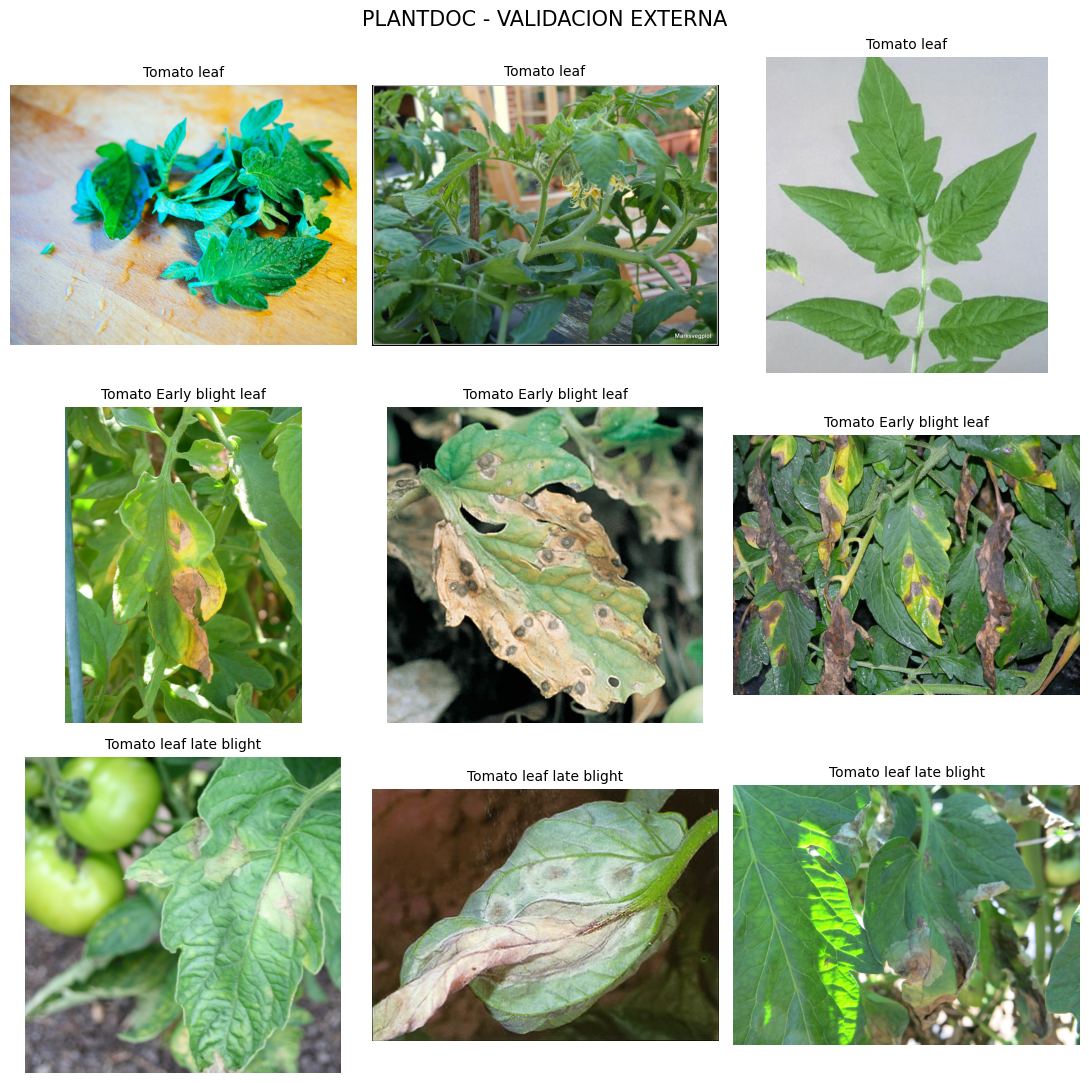


Archivo guardado: results/plantdoc_manifest.csv


In [ ]:
# 44. PREPARAR VALIDACION EXTERNA

from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import random
import os

base = Path("data/plantdoc")

equivalencias = {
    "Tomato leaf": "Tomato___healthy",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato leaf late blight": "Tomato___Late_blight"
}

registros = []

for division in ["train", "test"]:

    for carpeta, etiqueta in equivalencias.items():

        ruta = base / division / carpeta

        if not ruta.exists():
            print("Carpeta no encontrada:", ruta)
            continue

        for archivo in sorted(ruta.iterdir()):

            if archivo.suffix.lower() not in [
                ".jpg", ".jpeg", ".png", ".webp"
            ]:
                continue

            registros.append({
                "division": division,
                "ruta": str(archivo),
                "clase_original": carpeta,
                "etiqueta_real": etiqueta
            })

df_plantdoc = pd.DataFrame(registros)

print("DISTRIBUCION DE PLANTDOC")

display(
    pd.crosstab(
        df_plantdoc["division"],
        df_plantdoc["etiqueta_real"]
    )
)

print("\nTotal seleccionado:", len(df_plantdoc))

# Verificar que las imagenes pueden abrirse
errores = []

for ruta in df_plantdoc["ruta"]:

    try:
        with Image.open(ruta) as imagen:
            imagen.verify()
    except Exception as error:
        errores.append((ruta, str(error)))

print("Imagenes con errores:", len(errores))

if errores:
    print(errores[:10])

# Mostrar ejemplos de las tres categorias
fig, axes = plt.subplots(
    3, 3,
    figsize=(11, 11)
)

random.seed(42)

for fila, (carpeta, etiqueta) in enumerate(
    equivalencias.items()
):

    disponibles = df_plantdoc[
        (df_plantdoc["division"] == "test") &
        (df_plantdoc["etiqueta_real"] == etiqueta)
    ]

    ejemplos = disponibles.sample(
        n=min(3, len(disponibles)),
        random_state=42
    )

    for columna in range(3):

        ax = axes[fila, columna]
        ax.axis("off")

        if columna >= len(ejemplos):
            continue

        ruta = ejemplos.iloc[columna]["ruta"]

        with Image.open(ruta) as imagen:
            ax.imshow(imagen.convert("RGB"))

        ax.set_title(
            carpeta,
            fontsize=10
        )

plt.suptitle(
    "PLANTDOC - VALIDACION EXTERNA",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Guardar manifiesto para reproducibilidad
os.makedirs("results", exist_ok=True)

df_plantdoc.to_csv(
    "results/plantdoc_manifest.csv",
    index=False
)

print(
    "\nArchivo guardado:",
    "results/plantdoc_manifest.csv"
)


In [ ]:
# 45. PREPARAR IMAGENES DE PRUEBA PLANTDOC

import pandas as pd
from pathlib import Path
from PIL import Image
from IPython.display import display

# Cargar manifiesto generado anteriormente
df_plantdoc = pd.read_csv(
    "results/plantdoc_manifest.csv"
)

# Seleccionar exclusivamente el conjunto test
plantdoc_test = (
    df_plantdoc[
        df_plantdoc["division"] == "test"
    ]
    .sort_values(
        ["etiqueta_real", "ruta"]
    )
    .reset_index(drop=True)
    .copy()
)

# Asignar identificador reproducible
plantdoc_test.insert(
    0,
    "indice",
    range(len(plantdoc_test))
)

# Verificar existencia y lectura de imagenes
imagenes_validas = []

for _, fila in plantdoc_test.iterrows():

    ruta = Path(fila["ruta"])

    if not ruta.is_file():
        raise FileNotFoundError(
            f"No existe la imagen: {ruta}"
        )

    with Image.open(ruta) as imagen:
        imagen.load()

    imagenes_validas.append(str(ruta))

# Comprobar etiquetas
clases_esperadas = {
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
}

assert set(
    plantdoc_test["etiqueta_real"]
) == clases_esperadas

assert len(plantdoc_test) == 27

assert plantdoc_test["ruta"].is_unique

print("_" * 55)
print("PLANTDOC - CONJUNTO EXTERNO DE PRUEBA")
print("_" * 55)

print("\nTotal de imagenes:", len(plantdoc_test))

print("\nDistribucion:")
print(
    plantdoc_test["etiqueta_real"]
    .value_counts()
    .to_string()
)

print("\nPrimeros registros:")
display(plantdoc_test.head())

# Guardar lista exacta de evaluacion
plantdoc_test.to_csv(
    "results/plantdoc_test.csv",
    index=False
)

print("\nArchivo guardado:")
print("results/plantdoc_test.csv")

print("\nPREPARACION COMPLETADA")


_______________________________________________________
PLANTDOC - CONJUNTO EXTERNO DE PRUEBA
_______________________________________________________

Total de imagenes: 27

Distribucion:
etiqueta_real
Tomato___Late_blight     10
Tomato___Early_blight     9
Tomato___healthy          8

Primeros registros:


,indice,division,ruta,clase_original,etiqueta_real
0,0,test,data/plantdoc/test/Tomato Early blight leaf/03...,Tomato Early blight leaf,Tomato___Early_blight
1,1,test,data/plantdoc/test/Tomato Early blight leaf/10...,Tomato Early blight leaf,Tomato___Early_blight
2,2,test,data/plantdoc/test/Tomato Early blight leaf/12...,Tomato Early blight leaf,Tomato___Early_blight
3,3,test,data/plantdoc/test/Tomato Early blight leaf/Sh...,Tomato Early blight leaf,Tomato___Early_blight
4,4,test,data/plantdoc/test/Tomato Early blight leaf/bu...,Tomato Early blight leaf,Tomato___Early_blight



Archivo guardado:
results/plantdoc_test.csv

PREPARACION COMPLETADA


In [ ]:
# 46. VISION TRANSFORMER - PLANTDOC


import os
import time
import numpy as np
import pandas as pd
import torch

from PIL import Image
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification
)
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

modelo_id = "kimcomehome/plantvillage-vit-leaf-disease"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

# Cargar modelo y procesador originales
processor = AutoImageProcessor.from_pretrained(modelo_id)

modelo_vit_plantdoc = (
    AutoModelForImageClassification
    .from_pretrained(modelo_id)
    .to(device)
)

modelo_vit_plantdoc.eval()

# Las tres etiquetas que queremos evaluar
clases_objetivo = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

resultados = []

# Calentamiento de GPU
with torch.inference_mode():
    with Image.open(
        plantdoc_test.iloc[0]["ruta"]
    ) as img:
        imagen = img.convert("RGB")

    entradas = processor(
        images=imagen,
        return_tensors="pt"
    ).to(device)

    for _ in range(5):
        _ = modelo_vit_plantdoc(**entradas)

    if device.type == "cuda":
        torch.cuda.synchronize()

# Inferencia
for _, fila in plantdoc_test.iterrows():

    with Image.open(fila["ruta"]) as img:
        imagen = img.convert("RGB")

    entradas = processor(
        images=imagen,
        return_tensors="pt"
    ).to(device)

    if device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    with torch.inference_mode():
        salida = modelo_vit_plantdoc(**entradas)

    if device.type == "cuda":
        torch.cuda.synchronize()

    latencia_ms = (
        time.perf_counter() - inicio
    ) * 1000

    probabilidades = torch.softmax(
        salida.logits, dim=-1
    )[0]

    indice_predicho = int(
        probabilidades.argmax().item()
    )

    etiqueta_predicha = (
        modelo_vit_plantdoc.config.id2label[
            indice_predicho
        ]
    )

    confianza = float(
        probabilidades[indice_predicho].item()
    )

    resultados.append({
        "indice": int(fila["indice"]),
        "ruta": fila["ruta"],
        "etiqueta_real": fila["etiqueta_real"],
        "prediccion": etiqueta_predicha,
        "confianza": confianza,
        "latencia_ms": latencia_ms,
        "correcta": (
            etiqueta_predicha == fila["etiqueta_real"]
        )
    })

df_vit_plantdoc = pd.DataFrame(resultados)

# Metricas
y_real = df_vit_plantdoc["etiqueta_real"]
y_pred = df_vit_plantdoc["prediccion"]

accuracy = accuracy_score(y_real, y_pred)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        y_real,
        y_pred,
        labels=clases_objetivo,
        average="macro",
        zero_division=0
    )
)

latencia = df_vit_plantdoc["latencia_ms"].mean()

otras_clases = (
    ~df_vit_plantdoc["prediccion"]
    .isin(clases_objetivo)
).sum()

print("\n" + "_" * 55)
print("RESULTADOS VISION TRANSFORMER - PLANTDOC")
print("_" * 55)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision macro: {precision:.4f}")
print(f"Recall macro: {recall:.4f}")
print(f"F1 macro: {f1:.4f}")
print(f"Latencia media: {latencia:.2f} ms")
print(f"Predicciones fuera de las 3 clases: {otras_clases}")

print("\nREPORTE POR CLASE:")

print(
    classification_report(
        y_real,
        y_pred,
        labels=clases_objetivo,
        zero_division=0
    )
)

print("\nPREDICCIONES:")

display(
    df_vit_plantdoc[
        [
            "indice",
            "etiqueta_real",
            "prediccion",
            "confianza",
            "correcta"
        ]
    ]
)

# Guardar resultados
os.makedirs("results", exist_ok=True)

df_vit_plantdoc.to_csv(
    "results/predicciones_vit_plantdoc.csv",
    index=False
)

pd.DataFrame([{
    "Modelo": "Vision Transformer",
    "Dataset": "PlantDoc",
    "Imagenes": len(df_vit_plantdoc),
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Latencia (ms)": latencia,
    "Predicciones otras clases": int(otras_clases)
}]).to_csv(
    "results/metricas_vit_plantdoc.csv",
    index=False
)

print("\nArchivos guardados correctamente")


Dispositivo: cuda


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]


_______________________________________________________
RESULTADOS VISION TRANSFORMER - PLANTDOC
_______________________________________________________
Accuracy: 0.6296
Precision macro: 0.4359
Recall macro: 0.6000
F1 macro: 0.5046
Latencia media: 16.22 ms
Predicciones fuera de las 3 clases: 1

REPORTE POR CLASE:
                       precision    recall  f1-score   support

     Tomato___healthy       0.00      0.00      0.00         8
Tomato___Early_blight       0.69      1.00      0.82         9
 Tomato___Late_blight       0.62      0.80      0.70        10

            micro avg       0.65      0.63      0.64        27
            macro avg       0.44      0.60      0.50        27
         weighted avg       0.46      0.63      0.53        27


PREDICCIONES:


,indice,etiqueta_real,prediccion,confianza,correcta
0,0,Tomato___Early_blight,Tomato___Early_blight,0.263182,True
1,1,Tomato___Early_blight,Tomato___Early_blight,0.846863,True
2,2,Tomato___Early_blight,Tomato___Early_blight,0.959278,True
3,3,Tomato___Early_blight,Tomato___Early_blight,0.548295,True
4,4,Tomato___Early_blight,Tomato___Early_blight,0.864499,True
5,5,Tomato___Early_blight,Tomato___Early_blight,0.660214,True
6,6,Tomato___Early_blight,Tomato___Early_blight,0.970517,True
7,7,Tomato___Early_blight,Tomato___Early_blight,0.947365,True
8,8,Tomato___Early_blight,Tomato___Early_blight,0.966925,True
9,9,Tomato___Late_blight,Tomato___Late_blight,0.984453,True



Archivos guardados correctamente


In [ ]:
# 45A. RECUPERAR ETIQUETAS DE EFFICIENTNET


from datasets import load_dataset

# Ya esta disponible en cache de Colab
ds_etiquetas = load_dataset(
    "BrandonFors/Plant-Diseases-PlantVillage-Dataset",
    split="train[:1]"
)

# Obtener etiquetas del dataset
feature_label = ds_etiquetas.features["label"]

clases_effnet = feature_label.names

print("_" * 55)
print("CLASES DEL DATASET")
print("_" * 55)

print("Total de clases:", len(clases_effnet))

for indice, nombre in enumerate(clases_effnet):
    print(f"{indice:02d}: {nombre}")

assert len(clases_effnet) == 38, (
    "Se esperaban 38 clases"
)

print("\nETIQUETAS RECUPERADAS")


_______________________________________________________
CLASES DEL DATASET
_______________________________________________________
Total de clases: 38
00: Apple___Apple_scab
01: Apple___Black_rot
02: Apple___Cedar_apple_rust
03: Apple___healthy
04: Blueberry___healthy
05: Cherry_(including_sour)___Powdery_mildew
06: Cherry_(including_sour)___healthy
07: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
08: Corn_(maize)___Common_rust_
09: Corn_(maize)___Northern_Leaf_Blight
10: Corn_(maize)___healthy
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14: Grape___healthy
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___Late_blight
22: Potato___healthy
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___Leaf_scorch
27: Strawberry___healthy
28: Tomato___Bacter

In [ ]:
# 47. EFFICIENTNETV2-S - PLANTDOC


import os
import time
import torch
import pandas as pd

from PIL import Image
from torchvision.models import (
    efficientnet_v2_s,
    EfficientNet_V2_S_Weights
)
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

modelo_id = "BrandonFors/effnetv2_s_plant_disease"

# Cargar las etiquetas originales del dataset
from datasets import load_dataset

ds_etiquetas = load_dataset(
    "BrandonFors/Plant-Diseases-PlantVillage-Dataset",
    split="train[:1]"
)

# Intentar recuperar las 38 clases desde la configuracion
# ya utilizada en la evaluacion anterior.
print("Columnas disponibles:", ds_etiquetas.column_names)

# Usar el mismo orden de clases de la evaluacion anterior.
# Este orden debe corresponder exactamente a las salidas
# del checkpoint EfficientNet.
if "clases_effnet" not in globals():
    raise RuntimeError(
        "Necesitamos recuperar la lista 'clases_effnet' "
        "de la evaluacion anterior para evitar asignar "
        "etiquetas incorrectas."
    )

assert len(clases_effnet) == 38

# Arquitectura original
modelo_effnet_plantdoc = efficientnet_v2_s(
    num_classes=38
)

ruta_pesos = hf_hub_download(
    repo_id=modelo_id,
    filename="model.safetensors"
)

pesos = load_file(ruta_pesos)

# El checkpoint usa el prefijo 'model.'
pesos = {
    k.removeprefix("model."): v
    for k, v in pesos.items()
}

modelo_effnet_plantdoc.load_state_dict(
    pesos,
    strict=True
)

modelo_effnet_plantdoc = (
    modelo_effnet_plantdoc.to(device).eval()
)

transformacion = (
    EfficientNet_V2_S_Weights.DEFAULT.transforms()
)

# Calentamiento
with Image.open(plantdoc_test.iloc[0]["ruta"]) as img:
    imagen = img.convert("RGB")

entrada = (
    transformacion(imagen)
    .unsqueeze(0)
    .to(device)
)

with torch.inference_mode():
    for _ in range(5):
        _ = modelo_effnet_plantdoc(entrada)

if device.type == "cuda":
    torch.cuda.synchronize()

resultados_effnet = []

for _, fila in plantdoc_test.iterrows():

    with Image.open(fila["ruta"]) as img:
        imagen = img.convert("RGB")

    entrada = (
        transformacion(imagen)
        .unsqueeze(0)
        .to(device)
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    inicio = time.perf_counter()

    with torch.inference_mode():
        salida = modelo_effnet_plantdoc(entrada)

    if device.type == "cuda":
        torch.cuda.synchronize()

    latencia_ms = (
        time.perf_counter() - inicio
    ) * 1000

    probabilidades = torch.softmax(
        salida, dim=1
    )[0]

    indice_predicho = int(
        probabilidades.argmax().item()
    )

    etiqueta_predicha = clases_effnet[
        indice_predicho
    ]

    resultados_effnet.append({
        "indice": int(fila["indice"]),
        "ruta": fila["ruta"],
        "etiqueta_real": fila["etiqueta_real"],
        "prediccion": etiqueta_predicha,
        "confianza": float(
            probabilidades[indice_predicho].item()
        ),
        "latencia_ms": latencia_ms,
        "correcta": (
            etiqueta_predicha == fila["etiqueta_real"]
        )
    })

df_effnet_plantdoc = pd.DataFrame(
    resultados_effnet
)

clases_objetivo = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

y_real = df_effnet_plantdoc["etiqueta_real"]
y_pred = df_effnet_plantdoc["prediccion"]

accuracy = accuracy_score(y_real, y_pred)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        y_real,
        y_pred,
        labels=clases_objetivo,
        average="macro",
        zero_division=0
    )
)

otras = int(
    (~y_pred.isin(clases_objetivo)).sum()
)

latencia = df_effnet_plantdoc[
    "latencia_ms"
].mean()

print("\n" + "=" * 55)
print("RESULTADOS EFFICIENTNETV2-S - PLANTDOC")
print("=" * 55)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision macro: {precision:.4f}")
print(f"Recall macro: {recall:.4f}")
print(f"F1 macro: {f1:.4f}")
print(f"Latencia media: {latencia:.2f} ms")
print(f"Predicciones fuera de las 3 clases: {otras}")

print("\nREPORTE POR CLASE:")

print(
    classification_report(
        y_real,
        y_pred,
        labels=clases_objetivo,
        zero_division=0
    )
)

display(
    df_effnet_plantdoc[
        [
            "indice",
            "etiqueta_real",
            "prediccion",
            "confianza",
            "correcta"
        ]
    ]
)

os.makedirs("results", exist_ok=True)

df_effnet_plantdoc.to_csv(
    "results/predicciones_effnet_plantdoc.csv",
    index=False
)

pd.DataFrame([{
    "Modelo": "EfficientNetV2-S",
    "Dataset": "PlantDoc",
    "Imagenes": len(df_effnet_plantdoc),
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Latencia (ms)": latencia,
    "Predicciones otras clases": otras
}]).to_csv(
    "results/metricas_effnet_plantdoc.csv",
    index=False
)

print("\nArchivos guardados correctamente")


Columnas disponibles: ['image', 'label']

RESULTADOS EFFICIENTNETV2-S - PLANTDOC
Accuracy: 0.5556
Precision macro: 0.7857
Recall macro: 0.5565
F1 macro: 0.6512
Latencia media: 36.52 ms
Predicciones fuera de las 3 clases: 8

REPORTE POR CLASE:
                       precision    recall  f1-score   support

     Tomato___healthy       0.83      0.62      0.71         8
Tomato___Early_blight       0.67      0.44      0.53         9
 Tomato___Late_blight       0.86      0.60      0.71        10

            micro avg       0.79      0.56      0.65        27
            macro avg       0.79      0.56      0.65        27
         weighted avg       0.79      0.56      0.65        27



,indice,etiqueta_real,prediccion,confianza,correcta
0,0,Tomato___Early_blight,Tomato___Early_blight,0.748253,True
1,1,Tomato___Early_blight,Tomato___Early_blight,0.997127,True
2,2,Tomato___Early_blight,Tomato___Late_blight,0.665677,False
3,3,Tomato___Early_blight,Grape___Black_rot,0.982610,False
4,4,Tomato___Early_blight,Tomato___healthy,0.989623,False
5,5,Tomato___Early_blight,Grape___Black_rot,0.831019,False
6,6,Tomato___Early_blight,Tomato___Early_blight,0.999982,True
7,7,Tomato___Early_blight,"Pepper,_bell___healthy",0.751220,False
8,8,Tomato___Early_blight,Tomato___Early_blight,0.997931,True
9,9,Tomato___Late_blight,Tomato___Late_blight,0.999788,True



Archivos guardados correctamente


In [ ]:
# 48. COMPARACION PLANTVILLAGE VS PLANTDOC


import pandas as pd
import os

archivos = [
    ("Vision Transformer", "PlantVillage",
     "results/metricas_vit.csv"),

    ("Vision Transformer", "PlantDoc",
     "results/metricas_vit_plantdoc.csv"),

    ("EfficientNetV2-S", "PlantVillage",
     "results/metricas_effnet.csv"),

    ("EfficientNetV2-S", "PlantDoc",
     "results/metricas_effnet_plantdoc.csv")
]

registros = []

for modelo, dataset, ruta in archivos:

    df = pd.read_csv(ruta)
    fila = df.iloc[0]

    registros.append({
        "Modelo": modelo,
        "Dataset": dataset,
        "Accuracy": float(fila["Accuracy"]),
        "Precision": float(fila["Precision"]),
        "Recall": float(fila["Recall"]),
        "F1-score": float(fila["F1-score"]),
        "Latencia (ms)": float(fila["Latencia (ms)"])
    })

comparacion_externa = pd.DataFrame(registros)

print("_" * 60)
print("COMPARACION ENTRE DATASETS")
print("_" * 60)

display(
    comparacion_externa.round(4)
)

# Calcular disminucion de accuracy
resumen = []

for modelo in comparacion_externa["Modelo"].unique():

    datos = comparacion_externa[
        comparacion_externa["Modelo"] == modelo
    ]

    acc_pv = datos.loc[
        datos["Dataset"] == "PlantVillage",
        "Accuracy"
    ].iloc[0]

    acc_pd = datos.loc[
        datos["Dataset"] == "PlantDoc",
        "Accuracy"
    ].iloc[0]

    resumen.append({
        "Modelo": modelo,
        "Accuracy PlantVillage": acc_pv,
        "Accuracy PlantDoc": acc_pd,
        "Diferencia puntos porcentuales":
            (acc_pd - acc_pv) * 100
    })

df_diferencias = pd.DataFrame(resumen)

print("\nDIFERENCIAS DE ACCURACY:")
display(df_diferencias.round(4))

os.makedirs("results", exist_ok=True)

comparacion_externa.to_csv(
    "results/comparacion_datasets.csv",
    index=False
)

df_diferencias.to_csv(
    "results/diferencias_accuracy.csv",
    index=False
)

print("\nArchivos guardados correctamente")


____________________________________________________________
COMPARACION ENTRE DATASETS
____________________________________________________________


,Modelo,Dataset,Accuracy,Precision,Recall,F1-score,Latencia (ms)
0,Vision Transformer,PlantVillage,0.9989,0.9990,0.9991,0.9991,13.6096
1,Vision Transformer,PlantDoc,0.6296,0.4359,0.6000,0.5046,16.2176
2,EfficientNetV2-S,PlantVillage,0.9989,0.9990,0.9991,0.9991,26.1818
3,EfficientNetV2-S,PlantDoc,0.5556,0.7857,0.5565,0.6512,36.5150



DIFERENCIAS DE ACCURACY:


,Modelo,Accuracy PlantVillage,Accuracy PlantDoc,Diferencia puntos porcentuales
0,Vision Transformer,0.9989,0.6296,-36.9269
1,EfficientNetV2-S,0.9989,0.5556,-44.3343



Archivos guardados correctamente


In [ ]:
# 49. LOCALIZAR RESNET-50 EN COLAB

import os
import tensorflow as tf

print("Version TensorFlow:", tf.__version__)

print("\nMODELOS KERAS EN MEMORIA")

modelos_encontrados = []

for nombre, valor in list(globals().items()):

    if isinstance(valor, tf.keras.Model):
        modelos_encontrados.append(nombre)

        print(
            f"{nombre}: "
            f"{valor.count_params():,} parametros"
        )

if not modelos_encontrados:
    print("No hay modelos tf.keras.Model en memoria")

print("\nARCHIVOS KERAS DISPONIBLES")

archivos_keras = []

for carpeta in [".", "models", "modelos", "data"]:

    if not os.path.isdir(carpeta):
        continue

    for raiz, directorios, archivos in os.walk(carpeta):

        # Evitar recorridos demasiado extensos
        directorios[:] = [
            d for d in directorios
            if d not in [".git", ".cache", "__pycache__"]
        ]

        for archivo in archivos:

            if archivo.endswith((".keras", ".h5")):
                ruta = os.path.join(raiz, archivo)
                archivos_keras.append(ruta)
                print(ruta)

if not archivos_keras:
    print("No se encontraron archivos .keras o .h5")

print("\nBUSQUEDA FINALIZADA")


Version TensorFlow: 2.21.0

MODELOS KERAS EN MEMORIA
modelo_resnet: 24,788,134 parametros

ARCHIVOS KERAS DISPONIBLES
No se encontraron archivos .keras o .h5

BUSQUEDA FINALIZADA


In [ ]:

# 51. LOCALIZAR ETIQUETAS RESNET-50

import json
import pandas as pd

print("_" * 60)
print("BUSQUEDA DE ETIQUETAS RESNET-50")
print("_" * 60)

# 1. Buscar variables que puedan contener
# el orden de las 38 clases
for nombre, valor in list(globals().items()):

    if nombre.startswith("_"):
        continue

    if any(
        palabra in nombre.lower()
        for palabra in [
            "clase",
            "label",
            "class",
            "indice",
            "mapping"
        ]
    ):

        if isinstance(valor, (list, tuple)):

            if len(valor) == 38:
                print(
                    "\nVariable encontrada:",
                    nombre
                )
                print("Tipo:", type(valor).__name__)
                print("Primeras 5:", valor[:5])
                print("Ultimas 5:", valor[-5:])

        elif isinstance(valor, dict):

            if len(valor) == 38:
                print(
                    "\nDiccionario encontrado:",
                    nombre
                )
                print(
                    "Primeros elementos:",
                    list(valor.items())[:5]
                )

# 2. Inspeccionar atributos del modelo
print("\n=== ATRIBUTOS DEL MODELO ===")

for atributo in [
    "class_names",
    "classes",
    "labels",
    "class_indices",
    "id2label",
    "label2id"
]:

    if hasattr(modelo_resnet, atributo):

        print(
            atributo,
            "=",
            getattr(modelo_resnet, atributo)
        )

# 3. Revisar predicciones anteriores
print("\n=== ETIQUETAS DE PREDICCIONES ANTERIORES ===")

df_anterior = pd.read_csv(
    "results/predicciones_resnet.csv"
)

print(
    "Columnas:",
    df_anterior.columns.tolist()
)

print("\nEtiquetas predichas:")
print(
    sorted(
        df_anterior["prediccion"]
        .dropna()
        .unique()
    )
)

print("\nBUSQUEDA FINALIZADA")


____________________________________________________________
BUSQUEDA DE ETIQUETAS RESNET-50
____________________________________________________________

Diccionario encontrado: id2label
Primeros elementos: [(0, 'Apple___Apple_scab'), (1, 'Apple___Black_rot'), (2, 'Apple___Cedar_apple_rust'), (3, 'Apple___healthy'), (4, 'Blueberry___healthy')]

Diccionario encontrado: id2label_effnet
Primeros elementos: [(0, 'Apple___Apple_scab'), (1, 'Apple___Black_rot'), (10, 'Corn_(maize)___healthy'), (11, 'Grape___Black_rot'), (12, 'Grape___Esca_(Black_Measles)')]

Diccionario encontrado: id2label_resnet
Primeros elementos: [(0, 'Apple___Apple_scab'), (1, 'Apple___Black_rot'), (2, 'Apple___Cedar_apple_rust'), (3, 'Apple___healthy'), (4, 'Blueberry___healthy')]

Variable encontrada: clases_disponibles
Tipo: list
Primeras 5: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']
Ultimas 5: ['Tomato___Spider_mites Two-spotted_spider_mite', 'T

In [ ]:
# 52. RECUPERAR ETIQUETAS RESNET-50


import json

assert "id2label_resnet" in globals(), (
    "No se encontro id2label_resnet"
)

# Normalizar indices por si fueran cadenas
mapa_resnet = {
    int(indice): nombre
    for indice, nombre in id2label_resnet.items()
}

assert set(mapa_resnet.keys()) == set(range(38)), (
    "El mapa no contiene los indices 0 a 37"
)

clases_resnet = [
    mapa_resnet[i]
    for i in range(38)
]

assert len(set(clases_resnet)) == 38

print("_" * 55)
print("ETIQUETAS RESNET-50 RECUPERADAS")
print("_" * 55)

for indice, clase in enumerate(clases_resnet):
    print(f"{indice:02d}: {clase}")

print("\nTotal:", len(clases_resnet))

# Comparar con el orden de EfficientNet
print(
    "\nMismo orden que EfficientNet:",
    clases_resnet == clases_effnet
)

# Guardar el mapa utilizado
with open(
    "results/etiquetas_resnet.json",
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        mapa_resnet,
        archivo,
        ensure_ascii=False,
        indent=2
    )

print("\nArchivo guardado:")
print("results/etiquetas_resnet.json")

print("\nVERIFICACION COMPLETADA")


_______________________________________________________
ETIQUETAS RESNET-50 RECUPERADAS
_______________________________________________________
00: Apple___Apple_scab
01: Apple___Black_rot
02: Apple___Cedar_apple_rust
03: Apple___healthy
04: Blueberry___healthy
05: Cherry_(including_sour)___Powdery_mildew
06: Cherry_(including_sour)___healthy
07: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
08: Corn_(maize)___Common_rust_
09: Corn_(maize)___Northern_Leaf_Blight
10: Corn_(maize)___healthy
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14: Grape___healthy
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___Late_blight
22: Potato___healthy
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___Leaf_scorch
27: Strawberry___healthy
28: Tomato___Bacterial_spo

In [ ]:
# 50. RESNET-50 - PLANTDOC
#NOTA LO MOVI DE LUGAR PARA VOLVER A EJECUTARLO PERO PUEDE PERMANECER EN ESTE ORDEN

import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

# 1. Verificar modelo
assert "modelo_resnet" in globals(), (
    "No se encontro modelo_resnet"
)

assert "plantdoc_test" in globals(), (
    "No se encontro plantdoc_test"
)

assert modelo_resnet.output_shape[-1] == 38

# 2. Recuperar etiquetas utilizadas en la
# evaluacion original de ResNet-50
#
# Se reutiliza la lista si ya existe en memoria.
# No sustituir automaticamente por clases_effnet.

if "clases_resnet" not in globals():
    print(
        "ATENCION: falta la variable clases_resnet."
    )
    print(
        "Debemos recuperar el orden original "
        "antes de interpretar las predicciones."
    )
    raise RuntimeError(
        "No se puede evaluar sin el mapa de etiquetas."
    )

assert len(clases_resnet) == 38

# 3. Inferencia
resultados_resnet = []

# Calentamiento
with Image.open(
    plantdoc_test.iloc[0]["ruta"]
) as img:
    imagen = img.convert("RGB").resize((224, 224))

entrada = (
    np.asarray(imagen, dtype=np.float32) / 255.0
)[None, ...]

for _ in range(5):
    _ = modelo_resnet(
        entrada,
        training=False
    )

for _, fila in plantdoc_test.iterrows():

    with Image.open(fila["ruta"]) as img:
        imagen = img.convert("RGB").resize(
            (224, 224)
        )

    entrada = (
        np.asarray(
            imagen,
            dtype=np.float32
        ) / 255.0
    )[None, ...]

    inicio = time.perf_counter()

    salida = modelo_resnet(
        entrada,
        training=False
    )

    # Forzar sincronizacion de resultados
    probabilidades = np.asarray(
        salida
    )[0]

    latencia_ms = (
        time.perf_counter() - inicio
    ) * 1000

    # El modelo ya termina en softmax:
    # NO aplicar softmax nuevamente
    indice_predicho = int(
        np.argmax(probabilidades)
    )

    etiqueta_predicha = clases_resnet[
        indice_predicho
    ]

    resultados_resnet.append({
        "indice": int(fila["indice"]),
        "ruta": fila["ruta"],
        "etiqueta_real": fila["etiqueta_real"],
        "prediccion": etiqueta_predicha,
        "confianza": float(
            probabilidades[indice_predicho]
        ),
        "latencia_ms": latencia_ms,
        "correcta": (
            etiqueta_predicha == fila["etiqueta_real"]
        )
    })

df_resnet_plantdoc = pd.DataFrame(
    resultados_resnet
)

# 4. Metricas
clases_objetivo = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

y_real = df_resnet_plantdoc["etiqueta_real"]
y_pred = df_resnet_plantdoc["prediccion"]

accuracy = accuracy_score(
    y_real, y_pred
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        y_real,
        y_pred,
        labels=clases_objetivo,
        average="macro",
        zero_division=0
    )
)

latencia = df_resnet_plantdoc[
    "latencia_ms"
].mean()

otras_clases = int(
    (~y_pred.isin(clases_objetivo)).sum()
)

# 5. Resultados
print("\n" + "_" * 55)
print("RESULTADOS RESNET-50 - PLANTDOC")
print("_" * 55)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision macro: {precision:.4f}")
print(f"Recall macro: {recall:.4f}")
print(f"F1 macro: {f1:.4f}")
print(f"Latencia media: {latencia:.2f} ms")
print(
    "Predicciones fuera de las 3 clases:",
    otras_clases
)

print("\nREPORTE POR CLASE:")

print(
    classification_report(
        y_real,
        y_pred,
        labels=clases_objetivo,
        zero_division=0
    )
)

print("\nPREDICCIONES:")

display(
    df_resnet_plantdoc[
        [
            "indice",
            "etiqueta_real",
            "prediccion",
            "confianza",
            "correcta"
        ]
    ]
)

# 6. Guardar resultados
os.makedirs("results", exist_ok=True)

df_resnet_plantdoc.to_csv(
    "results/predicciones_resnet_plantdoc.csv",
    index=False
)

pd.DataFrame([{
    "Modelo": "ResNet-50",
    "Dataset": "PlantDoc",
    "Imagenes": len(df_resnet_plantdoc),
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Latencia (ms)": latencia,
    "Predicciones otras clases": otras_clases
}]).to_csv(
    "results/metricas_resnet_plantdoc.csv",
    index=False
)

print("\nArchivos guardados correctamente")


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)



_______________________________________________________
RESULTADOS RESNET-50 - PLANTDOC
_______________________________________________________
Accuracy: 0.2963
Precision macro: 0.4881
Recall macro: 0.2778
F1 macro: 0.3499
Latencia media: 574.69 ms
Predicciones fuera de las 3 clases: 16

REPORTE POR CLASE:
                       precision    recall  f1-score   support

     Tomato___healthy       0.00      0.00      0.00         8
Tomato___Early_blight       0.75      0.33      0.46         9
 Tomato___Late_blight       0.71      0.50      0.59        10

            micro avg       0.73      0.30      0.42        27
            macro avg       0.49      0.28      0.35        27
         weighted avg       0.51      0.30      0.37        27


PREDICCIONES:


,indice,etiqueta_real,prediccion,confianza,correcta
0,0,Tomato___Early_blight,Tomato___Late_blight,0.492236,False
1,1,Tomato___Early_blight,Tomato___Early_blight,0.658575,True
2,2,Tomato___Early_blight,Tomato___Late_blight,0.322941,False
3,3,Tomato___Early_blight,Strawberry___Leaf_scorch,0.318071,False
4,4,Tomato___Early_blight,Strawberry___Leaf_scorch,0.976364,False
5,5,Tomato___Early_blight,Strawberry___Leaf_scorch,0.986272,False
6,6,Tomato___Early_blight,Tomato___Early_blight,0.957871,True
7,7,Tomato___Early_blight,Grape___Black_rot,0.653866,False
8,8,Tomato___Early_blight,Tomato___Early_blight,0.833867,True
9,9,Tomato___Late_blight,Tomato___Late_blight,0.679981,True



Archivos guardados correctamente


In [ ]:

print("_" * 60)
print("DIAGNOSTICO RESNET-50 CORREGIDO")
print("_" * 60)

# 1. GPU
print("\nGPU disponibles:")
print(tf.config.list_physical_devices("GPU"))

# 2. Modelo
print("\nEntrada esperada:")
print(modelo_resnet.input_shape)

print("\nParametros:")
print(f"{modelo_resnet.count_params():,}")

# 3. Preparar imagen
with Image.open(plantdoc_test.iloc[0]["ruta"]) as img:
    imagen = img.convert("RGB").resize((224, 224))

entrada = (
    np.asarray(imagen, dtype=np.float32) / 255.0
)[None, ...]

tensor_entrada = tf.convert_to_tensor(
    entrada,
    dtype=tf.float32
)

# 4. Calentamiento
print("\nCalentando modelo...")

for _ in range(10):
    salida = modelo_resnet(
        tensor_entrada,
        training=False
    )
    _ = salida.numpy()

# 5. Medir 30 inferencias
print("Midiendo latencia...")

tiempos = []

for _ in range(30):

    inicio = time.perf_counter()

    salida = modelo_resnet(
        tensor_entrada,
        training=False
    )

    # Sincronizar antes de detener cronometro
    _ = salida.numpy()

    fin = time.perf_counter()

    tiempos.append(
        (fin - inicio) * 1000
    )

# 6. Resultados
print("\n" + "=" * 60)
print("RESULTADOS")
print("=" * 60)

print(f"Media:   {np.mean(tiempos):.2f} ms")
print(f"Mediana: {np.median(tiempos):.2f} ms")
print(f"Minima:  {np.min(tiempos):.2f} ms")
print(f"Maxima:  {np.max(tiempos):.2f} ms")

print("\nDIAGNOSTICO FINALIZADO")


____________________________________________________________
DIAGNOSTICO RESNET-50 CORREGIDO
____________________________________________________________

GPU disponibles:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Entrada esperada:
(None, 224, 224, 3)

Parametros:
24,788,134

Calentando modelo...
Midiendo latencia...

RESULTADOS
Media:   604.05 ms
Mediana: 503.09 ms
Minima:  346.40 ms
Maxima:  1955.43 ms

DIAGNOSTICO FINALIZADO


In [ ]:
# 53. DIAGNOSTICO DE LATENCIA RESNET-50


import tensorflow as tf
import numpy as np
import time
from PIL import Image

print("_" * 60)
print("DIAGNOSTICO DE RESNET-50")
print("_" * 60)

print("\nGPU disponibles:")
print(tf.config.list_physical_devices("GPU"))

print("\nDispositivo de variables del modelo:")
for variable in modelo_resnet.variables[:3]:
    print(variable.name, variable.device)

print("\nEntrada esperada:")
print(modelo_resnet.input_shape)

# Preparar una imagen de prueba
with Image.open(plantdoc_test.iloc[0]["ruta"]) as img:
    imagen = img.convert("RGB").resize((224, 224))

entrada = (
    np.asarray(imagen, dtype=np.float32) / 255.0
)[None, ...]

# Usar TensorFlow directamente
tensor_entrada = tf.convert_to_tensor(
    entrada,
    dtype=tf.float32
)

# Calentamiento
for _ in range(10):
    salida = modelo_resnet(
        tensor_entrada,
        training=False
    )
    _ = salida.numpy()

# Medicion repetida
tiempos = []

for _ in range(30):

    inicio = time.perf_counter()

    salida = modelo_resnet(
        tensor_entrada,
        training=False
    )

    _ = salida.numpy()

    tiempos.append(
        (time.perf_counter() - inicio) * 1000
    )

print("\nRESULTADOS")
print(
    f"Latencia media: {np.mean(tiempos):.2f} ms"
)
print(
    f"Latencia mediana: {np.median(tiempos):.2f} ms"
)
print(
    f"Latencia minima: {np.min(tiempos):.2f} ms"
)
print(
    f"Latencia maxima: {np.max(tiempos):.2f} ms"
)

print("\nDIAGNOSTICO FINALIZADO")


____________________________________________________________
DIAGNOSTICO DE RESNET-50
____________________________________________________________

GPU disponibles:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Dispositivo de variables del modelo:


AttributeError: 'Variable' object has no attribute 'device'

In [ ]:
# PASO 53 - CPU VS GPU RESNET-50


import tensorflow as tf
import numpy as np
import time

print("=" * 60)
print("COMPARACION CPU VS GPU - RESNET-50")
print("=" * 60)

print("\nDispositivos disponibles:")
print(tf.config.list_logical_devices())

# Reutilizamos tensor_entrada del paso anterior
assert "tensor_entrada" in globals()
assert "modelo_resnet" in globals()

def medir_dispositivo(dispositivo, repeticiones=10):

    tiempos = []

    with tf.device(dispositivo):

        # Calentamiento
        for _ in range(3):
            resultado = modelo_resnet(
                tensor_entrada,
                training=False
            )
            _ = resultado.numpy()

        # Mediciones
        for _ in range(repeticiones):

            inicio = time.perf_counter()

            resultado = modelo_resnet(
                tensor_entrada,
                training=False
            )

            _ = resultado.numpy()

            tiempos.append(
                (time.perf_counter() - inicio) * 1000
            )

    return tiempos

print("\nMidiendo CPU...")
tiempos_cpu = medir_dispositivo("/CPU:0")

print("\nMidiendo GPU...")
tiempos_gpu = medir_dispositivo("/GPU:0")

print("\n" + "=" * 60)
print("RESULTADOS")
print("=" * 60)

print(
    f"CPU media: {np.mean(tiempos_cpu):.2f} ms"
)
print(
    f"CPU mediana: {np.median(tiempos_cpu):.2f} ms"
)

print(
    f"GPU media: {np.mean(tiempos_gpu):.2f} ms"
)
print(
    f"GPU mediana: {np.median(tiempos_gpu):.2f} ms"
)

print("\nRelación CPU/GPU:")
print(
    f"{np.median(tiempos_cpu) / np.median(tiempos_gpu):.2f}x"
)

print("\nPRUEBA FINALIZADA")


COMPARACION CPU VS GPU - RESNET-50

Dispositivos disponibles:
[LogicalDevice(name='/device:CPU:0', device_type='CPU'), LogicalDevice(name='/device:GPU:0', device_type='GPU')]

Midiendo CPU...

Midiendo GPU...

RESULTADOS
CPU media: 1217.58 ms
CPU mediana: 923.53 ms
GPU media: 460.88 ms
GPU mediana: 448.91 ms

Relación CPU/GPU:
2.06x

PRUEBA FINALIZADA


In [ ]:
#AREGLANDO PROBLEMAS
import tensorflow as tf
import numpy as np
import time

print("=" * 60)
print("RESNET-50 - INFERENCIA CON TF.FUNCTION")
print("=" * 60)

# Crear funcion compilada
@tf.function(
    input_signature=[
        tf.TensorSpec(
            shape=[1, 224, 224, 3],
            dtype=tf.float32
        )
    ]
)
def inferencia_resnet(x):
    return modelo_resnet(x, training=False)

# Colocar entrada en GPU
with tf.device("/GPU:0"):
    entrada_gpu = tf.identity(tensor_entrada)

# Compilacion y calentamiento
print("\nCompilando y calentando...")

for _ in range(10):
    resultado = inferencia_resnet(entrada_gpu)
    _ = resultado.numpy()

# Medicion
tiempos = []

print("Midiendo 50 inferencias...")

for _ in range(50):

    inicio = time.perf_counter()

    resultado = inferencia_resnet(entrada_gpu)

    # Sincronizacion
    _ = resultado.numpy()

    tiempos.append(
        (time.perf_counter() - inicio) * 1000
    )

print("\n" + "_" * 60)
print("RESULTADOS TF.FUNCTION")
print("_" * 60)

print(f"Media:   {np.mean(tiempos):.2f} ms")
print(f"Mediana: {np.median(tiempos):.2f} ms")
print(f"Minima:  {np.min(tiempos):.2f} ms")
print(f"Maxima:  {np.max(tiempos):.2f} ms")

# Comprobar que las predicciones no cambiaron
salida_original = modelo_resnet(
    tensor_entrada,
    training=False
).numpy()

salida_compilada = inferencia_resnet(
    entrada_gpu
).numpy()

diferencia = np.max(
    np.abs(salida_original - salida_compilada)
)

print("\nDiferencia maxima entre salidas:")
print(diferencia)

print("\nPRUEBA FINALIZADA")


RESNET-50 - INFERENCIA CON TF.FUNCTION

Compilando y calentando...
Midiendo 50 inferencias...

RESULTADOS TF.FUNCTION
Media:   19.31 ms
Mediana: 16.35 ms
Minima:  13.38 ms
Maxima:  38.41 ms

Diferencia maxima entre salidas:
2.9802322e-07

PRUEBA FINALIZADA


In [ ]:
# PASO 54 - RESNET OPTIMIZADO EN PLANTDOC


import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

print("_" * 60)
print("RESNET-50 OPTIMIZADO - 27 IMAGENES PLANTDOC")
print("_" * 60)

resultados_optimizados = []

# Calentamiento adicional
for _ in range(10):
    salida = inferencia_resnet(entrada_gpu)
    _ = salida.numpy()

# Procesar las mismas 27 imagenes
for _, fila in plantdoc_test.iterrows():

    with Image.open(fila["ruta"]) as img:
        imagen = img.convert("RGB").resize((224, 224))

    entrada = (
        np.asarray(imagen, dtype=np.float32) / 255.0
    )[None, ...]

    tensor = tf.convert_to_tensor(
        entrada,
        dtype=tf.float32
    )

    # Excluir preparacion y transferencia
    # del tiempo de inferencia
    with tf.device("/GPU:0"):
        tensor = tf.identity(tensor)

    inicio = time.perf_counter()

    salida = inferencia_resnet(tensor)

    probabilidades = salida.numpy()[0]

    latencia_ms = (
        time.perf_counter() - inicio
    ) * 1000

    indice_predicho = int(
        np.argmax(probabilidades)
    )

    resultados_optimizados.append({
        "indice": int(fila["indice"]),
        "prediccion": clases_resnet[indice_predicho],
        "latencia_ms": latencia_ms
    })

df_resnet_optimizado = pd.DataFrame(
    resultados_optimizados
)

# Comparar predicciones con las originales
comparacion = df_resnet_plantdoc[
    ["indice", "prediccion"]
].merge(
    df_resnet_optimizado[
        ["indice", "prediccion"]
    ],
    on="indice",
    suffixes=("_original", "_optimizada"),
    validate="one_to_one"
)

coincidencias = (
    comparacion["prediccion_original"]
    == comparacion["prediccion_optimizada"]
).sum()

print("\nRESULTADOS")
print("-" * 60)

print(
    f"Imagenes evaluadas: {len(df_resnet_optimizado)}"
)

print(
    f"Predicciones coincidentes: "
    f"{coincidencias}/{len(comparacion)}"
)

print(
    f"Latencia media: "
    f"{df_resnet_optimizado['latencia_ms'].mean():.2f} ms"
)

print(
    f"Latencia mediana: "
    f"{df_resnet_optimizado['latencia_ms'].median():.2f} ms"
)

print(
    f"Latencia minima: "
    f"{df_resnet_optimizado['latencia_ms'].min():.2f} ms"
)

print(
    f"Latencia maxima: "
    f"{df_resnet_optimizado['latencia_ms'].max():.2f} ms"
)

# Guardar medicion optimizada sin sobrescribir
# los archivos originales
os.makedirs("results", exist_ok=True)

df_resnet_optimizado.to_csv(
    "results/latencia_resnet_optimizada_plantdoc.csv",
    index=False
)

print("\nArchivo guardado correctamente")


____________________________________________________________
RESNET-50 OPTIMIZADO - 27 IMAGENES PLANTDOC
____________________________________________________________

RESULTADOS
------------------------------------------------------------
Imagenes evaluadas: 27
Predicciones coincidentes: 27/27
Latencia media: 24.84 ms
Latencia mediana: 21.72 ms
Latencia minima: 20.53 ms
Latencia maxima: 45.59 ms

Archivo guardado correctamente


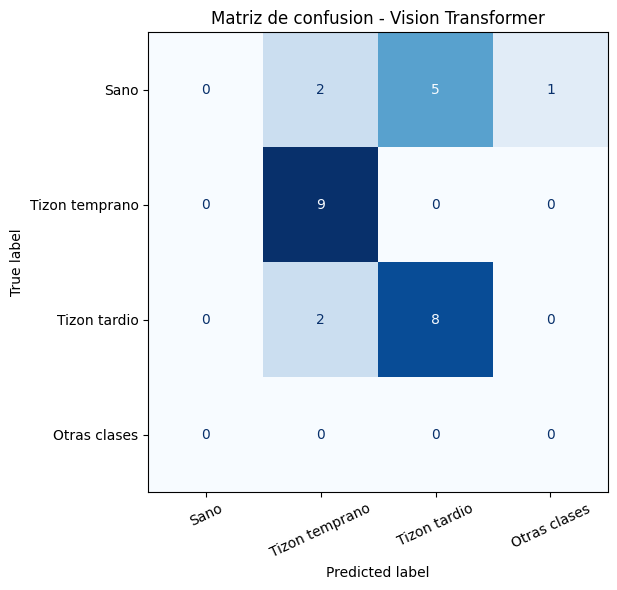

Guardada: results/matriz_confusion_vision_transformer_plantdoc.png


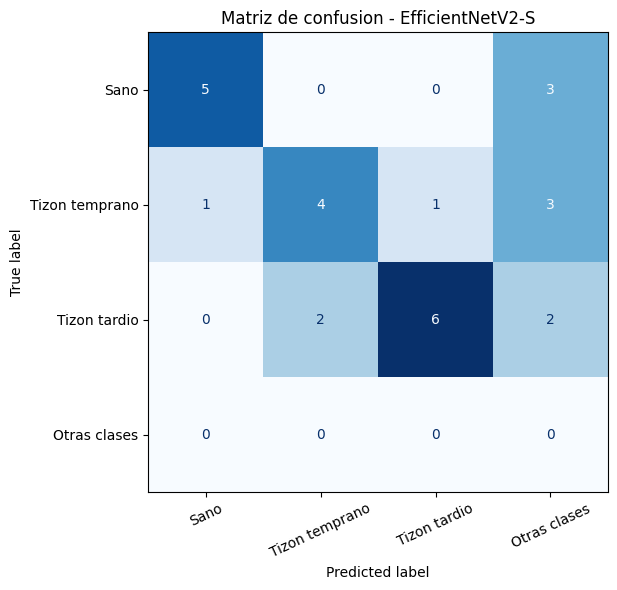

Guardada: results/matriz_confusion_efficientnetv2_s_plantdoc.png


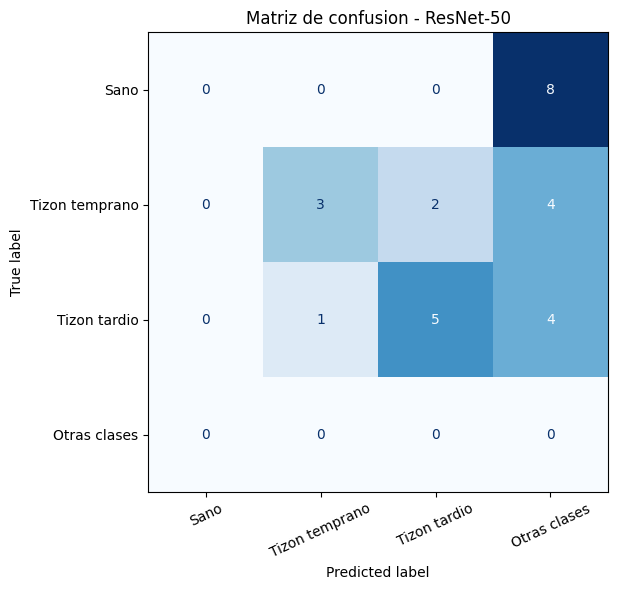

Guardada: results/matriz_confusion_resnet_50_plantdoc.png

PASO  COMPLETADO


In [ ]:
# PASO 55 - MATRICES DE CONFUSION PLANTDOC


import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

os.makedirs("results", exist_ok=True)

archivos = {
    "Vision Transformer": "results/predicciones_vit_plantdoc.csv",
    "EfficientNetV2-S": "results/predicciones_effnet_plantdoc.csv",
    "ResNet-50": "results/predicciones_resnet_plantdoc.csv"
}

etiquetas_objetivo = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
]

etiquetas_matriz = etiquetas_objetivo + ["Otras clases"]

nombres_cortos = [
    "Sano",
    "Tizon temprano",
    "Tizon tardio",
    "Otras clases"
]

def agrupar_etiqueta(etiqueta):
    if etiqueta in etiquetas_objetivo:
        return etiqueta
    return "Otras clases"

for nombre_modelo, ruta in archivos.items():

    df = pd.read_csv(ruta)

    assert len(df) == 27, (
        f"{nombre_modelo}: se esperaban 27 imagenes"
    )

    assert df["indice"].is_unique, (
        f"{nombre_modelo}: hay indices duplicados"
    )

    df = df.sort_values("indice")

    y_real = df["etiqueta_real"].map(
        agrupar_etiqueta
    )

    y_pred = df["prediccion"].map(
        agrupar_etiqueta
    )

    matriz = confusion_matrix(
        y_real,
        y_pred,
        labels=etiquetas_matriz
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=nombres_cortos
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"Matriz de confusion - {nombre_modelo}"
    )

    plt.xticks(rotation=25)
    plt.tight_layout()

    nombre_archivo = (
        nombre_modelo.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    ruta_salida = (
        f"results/matriz_confusion_"
        f"{nombre_archivo}_plantdoc.png"
    )

    plt.savefig(
        ruta_salida,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Guardada: {ruta_salida}")

print("\nPASO  COMPLETADO")


In [ ]:
# PASO 56 - ERRORES COMPARTIDOS PLANTDOC


import pandas as pd

archivos = {
    "ViT": "results/predicciones_vit_plantdoc.csv",
    "EfficientNet": "results/predicciones_effnet_plantdoc.csv",
    "ResNet": "results/predicciones_resnet_plantdoc.csv"
}

tablas = []

for nombre, ruta in archivos.items():

    df = pd.read_csv(ruta)

    df = df[
        ["indice", "etiqueta_real", "prediccion"]
    ].copy()

    df = df.rename(
        columns={
            "prediccion": f"pred_{nombre}"
        }
    )

    if tablas:
        df = df.drop(
            columns=["etiqueta_real"]
        )

    tablas.append(df)

comparacion = tablas[0]

for df in tablas[1:]:
    comparacion = comparacion.merge(
        df,
        on="indice",
        validate="one_to_one"
    )

modelos = ["ViT", "EfficientNet", "ResNet"]

for modelo in modelos:

    comparacion[f"error_{modelo}"] = (
        comparacion[f"pred_{modelo}"]
        != comparacion["etiqueta_real"]
    )

comparacion["total_errores"] = (
    comparacion[
        [f"error_{m}" for m in modelos]
    ].sum(axis=1)
)

errores_compartidos_plantdoc = (
    comparacion[
        comparacion["total_errores"] == 3
    ].copy()
)

print("_" * 60)
print("ANALISIS DE ERRORES COMPARTIDOS")
print("_" * 60)

print(
    "\nImagenes incorrectas por los 3 modelos:",
    len(errores_compartidos_plantdoc)
)

print(
    "\nImagenes correctas por los 3 modelos:",
    int((comparacion["total_errores"] == 0).sum())
)

print("\nDistribucion de errores:")
print(
    comparacion["total_errores"]
    .value_counts()
    .sort_index()
)

print("\nERRORES COMPARTIDOS:")

display(
    errores_compartidos_plantdoc[
        [
            "indice",
            "etiqueta_real",
            "pred_ViT",
            "pred_EfficientNet",
            "pred_ResNet"
        ]
    ]
)

comparacion.to_csv(
    "results/comparacion_predicciones_plantdoc.csv",
    index=False
)

errores_compartidos_plantdoc.to_csv(
    "results/errores_compartidos_plantdoc.csv",
    index=False
)

print("\nArchivos guardados correctamente")


____________________________________________________________
ANALISIS DE ERRORES COMPARTIDOS
____________________________________________________________

Imagenes incorrectas por los 3 modelos: 5

Imagenes correctas por los 3 modelos: 6

Distribucion de errores:
total_errores
0     6
1     6
2    10
3     5
Name: count, dtype: int64

ERRORES COMPARTIDOS:


,indice,etiqueta_real,pred_ViT,pred_EfficientNet,pred_ResNet
12,12,Tomato___Late_blight,Tomato___Early_blight,Strawberry___Leaf_scorch,Strawberry___Leaf_scorch
15,15,Tomato___Late_blight,Tomato___Early_blight,Tomato___Early_blight,Tomato___Early_blight
19,19,Tomato___healthy,Tomato___Leaf_Mold,Raspberry___healthy,Strawberry___healthy
20,20,Tomato___healthy,Tomato___Early_blight,Tomato___Leaf_Mold,Grape___Black_rot
26,26,Tomato___healthy,Tomato___Late_blight,Tomato___Tomato_mosaic_virus,Tomato___Tomato_Yellow_Leaf_Curl_Virus



Archivos guardados correctamente


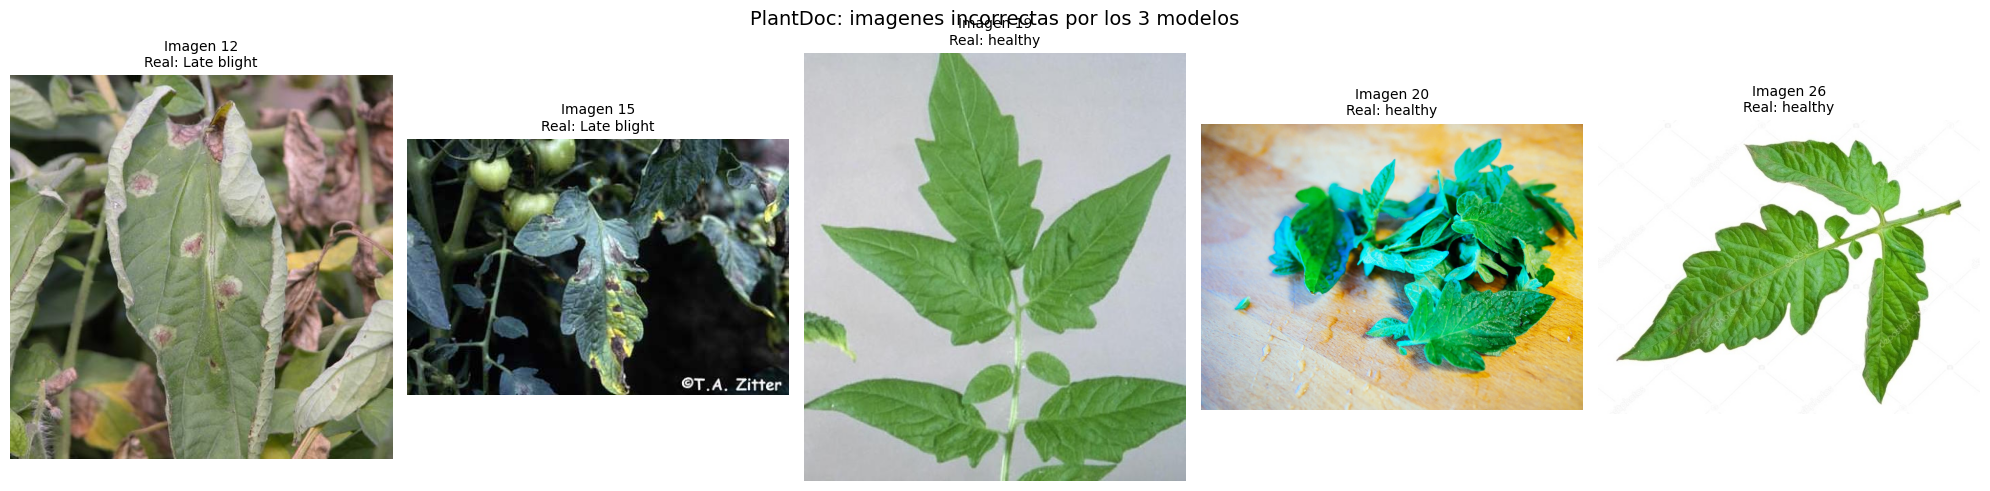

Imagen guardada correctamente


In [ ]:
# PASO 57 - VISUALIZAR ERRORES COMPARTIDOS


import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

errores = pd.read_csv(
    "results/errores_compartidos_plantdoc.csv"
)

manifest = pd.read_csv(
    "results/plantdoc_test.csv"
)

# Recuperar las rutas originales
errores = errores.merge(
    manifest[["indice", "ruta"]],
    on="indice",
    how="left",
    validate="one_to_one"
)

assert errores["ruta"].notna().all(), (
    "No se encontraron todas las rutas"
)

fig, axes = plt.subplots(
    1,
    len(errores),
    figsize=(20, 5)
)

for ax, (_, fila) in zip(axes, errores.iterrows()):

    with Image.open(fila["ruta"]) as img:
        imagen = img.convert("RGB").copy()

    ax.imshow(imagen)

    nombre_real = (
        fila["etiqueta_real"]
        .replace("Tomato___", "")
        .replace("_", " ")
    )

    ax.set_title(
        f"Imagen {fila['indice']}\n"
        f"Real: {nombre_real}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "PlantDoc: imagenes incorrectas por los 3 modelos",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "results/errores_compartidos_visual.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Imagen guardada correctamente")


In [ ]:

# PASO 58 - DUPLICADOS EXACTOS PLANTDOC

import os
import hashlib
import pandas as pd

def calcular_hash(ruta):

    sha = hashlib.sha256()

    with open(ruta, "rb") as archivo:

        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b""
        ):
            sha.update(bloque)

    return sha.hexdigest()

# Utilizar todas las imagenes de PlantDoc
manifest = pd.read_csv(
    "results/plantdoc_manifest.csv"
)

print("Columnas del manifiesto:")
print(manifest.columns.tolist())

print("\nPrimeros registros:")
display(manifest.head())

print("\nTotal de registros:", len(manifest))

# Localizar columna de rutas
columnas_ruta = [
    c for c in manifest.columns
    if c.lower() in ["ruta", "path", "filepath"]
]

if not columnas_ruta:
    raise ValueError(
        "No se encontro columna de rutas. "
        "Revisar el manifiesto antes de continuar."
    )

columna_ruta = columnas_ruta[0]

# Verificar archivos existentes
rutas = manifest[columna_ruta].dropna()

faltantes = [
    ruta for ruta in rutas
    if not os.path.isfile(ruta)
]

print("\nArchivos faltantes:", len(faltantes))

if faltantes:
    print("Ejemplos:", faltantes[:5])
    raise FileNotFoundError(
        "Hay rutas que deben corregirse."
    )

# Calcular hashes
manifest["sha256"] = manifest[
    columna_ruta
].apply(calcular_hash)

# Detectar duplicados
duplicados = manifest[
    manifest.duplicated(
        subset=["sha256"],
        keep=False
    )
].copy()

print("\n" + "=" * 55)
print("RESULTADOS DE DUPLICADOS EXACTOS")
print("=" * 55)

print(
    "Imagenes analizadas:",
    len(manifest)
)

print(
    "Hashes distintos:",
    manifest["sha256"].nunique()
)

print(
    "Registros involucrados en duplicados:",
    len(duplicados)
)

if not duplicados.empty:
    display(
        duplicados.sort_values("sha256")
    )

os.makedirs("results", exist_ok=True)

manifest.to_csv(
    "results/plantdoc_hashes.csv",
    index=False
)

duplicados.to_csv(
    "results/plantdoc_duplicados.csv",
    index=False
)

print("\nPASO 58 COMPLETADO")


Columnas del manifiesto:
['division', 'ruta', 'clase_original', 'etiqueta_real']

Primeros registros:


,division,ruta,clase_original,etiqueta_real
0,train,data/plantdoc/train/Tomato leaf/003.JPG.jpg,Tomato leaf,Tomato___healthy
1,train,data/plantdoc/train/Tomato leaf/009-e137376878...,Tomato leaf,Tomato___healthy
2,train,data/plantdoc/train/Tomato leaf/100_8283.jpg,Tomato leaf,Tomato___healthy
3,train,data/plantdoc/train/Tomato leaf/15481477375.jpg,Tomato leaf,Tomato___healthy
4,train,data/plantdoc/train/Tomato leaf/1686.jpg,Tomato leaf,Tomato___healthy



Total de registros: 262

Archivos faltantes: 0

RESULTADOS DE DUPLICADOS EXACTOS
Imagenes analizadas: 262
Hashes distintos: 262
Registros involucrados en duplicados: 0

PASO 55 COMPLETADO


In [ ]:
# PASO 59 - CONSOLIDACION DE RESULTADOS


import os
import pandas as pd

os.makedirs("results", exist_ok=True)

archivos = [
    ("ViT", "PlantVillage", "results/metricas_vit.csv"),
    ("EfficientNetV2-S", "PlantVillage", "results/metricas_effnet.csv"),
    ("ResNet-50", "PlantVillage", "results/metricas_resnet.csv"),
    ("ViT", "PlantDoc", "results/metricas_vit_plantdoc.csv"),
    ("EfficientNetV2-S", "PlantDoc", "results/metricas_effnet_plantdoc.csv"),
    ("ResNet-50", "PlantDoc", "results/metricas_resnet_plantdoc.csv")
]

print("_" * 60)
print("ARCHIVOS DE METRICAS")
print("_" * 60)

for modelo, dataset, ruta in archivos:

    df = pd.read_csv(ruta)

    print(f"\n{modelo} - {dataset}")
    print("Columnas:", df.columns.tolist())
    display(df.head(1))

print("\nINSPECCION COMPLETADA")


____________________________________________________________
ARCHIVOS DE METRICAS
____________________________________________________________

ViT - PlantVillage
Columnas: ['Modelo', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'Latencia (ms)', 'Parametros']


,Modelo,Accuracy,Precision,Recall,F1-score,Latencia (ms),Parametros
0,Vision Transformer,0.998899,0.998981,0.999127,0.999053,13.609575,85827878



EfficientNetV2-S - PlantVillage
Columnas: ['Modelo', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'Latencia (ms)', 'Parametros']


,Modelo,Accuracy,Precision,Recall,F1-score,Latencia (ms),Parametros
0,EfficientNetV2-S,0.998899,0.998981,0.999127,0.999053,26.181789,20226166



ResNet-50 - PlantVillage
Columnas: ['Modelo', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'Latencia (ms)', 'Parametros']


...


EfficientNetV2-S - PlantDoc
Columnas: ['Modelo', 'Dataset', 'Imagenes', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'Latencia (ms)', 'Predicciones otras clases']


,Modelo,Dataset,Imagenes,Accuracy,Precision,Recall,F1-score,Latencia (ms),Predicciones otras clases
0,EfficientNetV2-S,PlantDoc,27,0.555556,0.785714,0.556481,0.651167,36.51504,8



ResNet-50 - PlantDoc
Columnas: ['Modelo', 'Dataset', 'Imagenes', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'Latencia (ms)', 'Predicciones otras clases']


,Modelo,Dataset,Imagenes,Accuracy,Precision,Recall,F1-score,Latencia (ms),Predicciones otras clases
0,ResNet-50,PlantDoc,27,0.296296,0.488095,0.277778,0.349925,574.688806,16



INSPECCION COMPLETADA


In [ ]:
# PASO 60 - RESULTADOS DEFINITIVOS


import os
import pandas as pd

os.makedirs("results", exist_ok=True)

archivos = [
    ("ViT", "PlantVillage", "results/metricas_vit.csv", 908),
    ("EfficientNetV2-S", "PlantVillage", "results/metricas_effnet.csv", 908),
    ("ResNet-50", "PlantVillage", "results/metricas_resnet.csv", 908),
    ("ViT", "PlantDoc", "results/metricas_vit_plantdoc.csv", 27),
    ("EfficientNetV2-S", "PlantDoc", "results/metricas_effnet_plantdoc.csv", 27),
    ("ResNet-50", "PlantDoc", "results/metricas_resnet_plantdoc.csv", 27)
]

registros = []

for modelo, dataset, ruta, imagenes in archivos:

    df = pd.read_csv(ruta)
    assert len(df) == 1, f"Revisar {ruta}"

    fila = df.iloc[0]

    registros.append({
        "Modelo": modelo,
        "Dataset": dataset,
        "Imagenes": imagenes,
        "Accuracy": float(fila["Accuracy"]),
        "Precision_macro": float(fila["Precision"]),
        "Recall_macro": float(fila["Recall"]),
        "F1_macro": float(fila["F1-score"]),
        "Latencia_original_ms": float(
            fila["Latencia (ms)"]
        ),
        "Parametros": (
            int(fila["Parametros"])
            if "Parametros" in df.columns
            else None
        ),
        "Predicciones_fuera_de_clase": (
            int(fila["Predicciones otras clases"])
            if "Predicciones otras clases" in df.columns
            else None
        )
    })

resultados = pd.DataFrame(registros)

# Recuperar parametros desde PlantVillage
parametros = (
    resultados[resultados["Dataset"] == "PlantVillage"]
    .set_index("Modelo")["Parametros"]
    .to_dict()
)

resultados["Parametros"] = (
    resultados["Modelo"].map(parametros).astype(int)
)

# Registrar latencia optimizada solo para
# ResNet-50 en PlantDoc
resultados["Latencia_optimizada_ms"] = float("nan")

ruta_opt = (
    "results/latencia_resnet_optimizada_plantdoc.csv"
)

df_opt = pd.read_csv(ruta_opt)

assert len(df_opt) == 27
assert df_opt["indice"].is_unique

latencia_opt = df_opt["latencia_ms"].mean()

mascara = (
    (resultados["Modelo"] == "ResNet-50")
    & (resultados["Dataset"] == "PlantDoc")
)

resultados.loc[
    mascara, "Latencia_optimizada_ms"
] = latencia_opt

# Guardar resultados completos
resultados.to_csv(
    "results/resultados_finales.csv",
    index=False
)

print("_" * 60)
print("RESULTADOS FINALES")
print("_" * 60)

display(resultados.round(4))

# Comparacion entre datasets
tabla_accuracy = resultados.pivot(
    index="Modelo",
    columns="Dataset",
    values="Accuracy"
)

tabla_accuracy["Caida_pp"] = (
    tabla_accuracy["PlantVillage"]
    - tabla_accuracy["PlantDoc"]
) * 100

tabla_accuracy = tabla_accuracy.reset_index()

tabla_accuracy.to_csv(
    "results/comparacion_final.csv",
    index=False
)

print("\nCOMPARACION ENTRE DATASETS")
display(tabla_accuracy.round(4))

print("\nARCHIVOS GENERADOS:")
print("results/resultados_finales.csv")
print("results/comparacion_final.csv")

print("\nPASO 60 COMPLETADO")


____________________________________________________________
RESULTADOS FINALES
____________________________________________________________


,Modelo,Dataset,Imagenes,Accuracy,Precision_macro,Recall_macro,F1_macro,Latencia_original_ms,Parametros,Predicciones_fuera_de_clase,Latencia_optimizada_ms
0,ViT,PlantVillage,908,0.9989,0.9990,0.9991,0.9991,13.6096,85827878,NaN,NaN
1,EfficientNetV2-S,PlantVillage,908,0.9989,0.9990,0.9991,0.9991,26.1818,20226166,NaN,NaN
2,ResNet-50,PlantVillage,908,0.3293,0.6408,0.2958,0.3824,15.1465,24788134,NaN,NaN
3,ViT,PlantDoc,27,0.6296,0.4359,0.6000,0.5046,16.2176,85827878,1.0,NaN
4,EfficientNetV2-S,PlantDoc,27,0.5556,0.7857,0.5565,0.6512,36.5150,20226166,8.0,NaN
5,ResNet-50,PlantDoc,27,0.2963,0.4881,0.2778,0.3499,574.6888,24788134,16.0,24.8444



COMPARACION ENTRE DATASETS


Dataset,Modelo,PlantDoc,PlantVillage,Caida_pp
0,EfficientNetV2-S,0.5556,0.9989,44.3343
1,ResNet-50,0.2963,0.3293,3.2999
2,ViT,0.6296,0.9989,36.9269



ARCHIVOS GENERADOS:
results/resultados_finales.csv
results/comparacion_final.csv

PASO 60 COMPLETADO


In [ ]:
# PASO 61 - EXPORTAR RESULTADOS


import os
import zipfile
from google.colab import files

archivo_zip = "resultados_maestria_ia.zip"

with zipfile.ZipFile(
    archivo_zip,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for carpeta, subcarpetas, archivos in os.walk(
        "results"
    ):

        for archivo in archivos:

            ruta = os.path.join(carpeta, archivo)

            zipf.write(
                ruta,
                arcname=ruta
            )

print("Archivo generado:", archivo_zip)

print(
    "Tamano:",
    round(os.path.getsize(archivo_zip) / 1024, 2),
    "KB"
)

files.download(archivo_zip)


Archivo generado: resultados_maestria_ia.zip
Tamano: 3269.43 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>